# 05 — Recorrido Completo End-to-End de Resultados: Handwritten Font cGAN

**Proyecto:** Generación de Tipografía Manuscrita mediante cGAN Condicional (`Pix2Pix` y `StyleUNet` con `AdaIN`), Auditoría con Doble Evaluador CNN (`ResNet-18` y `EfficientNet-B0`), Explicabilidad Espacial (`Grad-CAM`), Detección OOD y Despliegue en Tiempo Real con **ONNX Runtime** + Exportación Instalable **`.ttf`**.  
**Autor:** Carlo A. Amezcua L. — *Deep Learning para Visión de Computadoras* (CUGDL, Universidad de Guadalajara).

> **Rol de este notebook y relación con los originales:** Este notebook maestro actúa como **síntesis ejecutiva reproducible** (**100 % en CPU en <30 segundos**, cero entrenamiento). Los notebooks por etapa (`01`–`04` y `eval/*`) junto con los scripts de `src/` y `eval/` son la **fuente de verdad** que entrenaron los modelos y generaron los reportes JSON de `results/`, los pesos `checkpoints/*.onnx` y las figuras de `docs/figuras/`; aquí se consolidan dichos artefactos junto con una prueba de inferencia real en vivo.

### Mapa del recorrido (7 secciones y fuente de origen)
1. **Problema, Vocabulario (75 símbolos), Datos y Protocolo Anti-Fuga** (`3,825` pares sintéticos, `300` trazos reales con stylus, `11` símbolos *Zero-Shot*, `72` imágenes OOD) — *Origen:* [`01_eda_datos.ipynb`](01_eda_datos.ipynb), [`docs/datasheet.md`](../docs/datasheet.md).
2. **Arquitectura y Flujo Tensorial (`1×128×128`)** — instanciación real en CPU, tabla exacta de parámetros, trazado espacial y justificación arquitectónica — *Origen:* [`src/models/`](../src/models/).
3. **Evolución Experimental y Comparativa Unificada** — curvas de entrenamiento, dominio sintético vs. stylus real, choque de grosor de trazo (`2.57 %` tinta) y salto de **`StyleUNet`** (`89.06 %` en `val`, `72.73 %` en *Zero-Shot*, `+63.64 pp` vs. `pix2pix_finetuned`) — *Origen:* [`02_colab_training.ipynb`](02_colab_training.ipynb), [`03_colab_finetuning.ipynb`](03_colab_finetuning.ipynb), [`04_colab_style_encoder.ipynb`](04_colab_style_encoder.ipynb), [`docs/bitacora_iteraciones.md`](../docs/bitacora_iteraciones.md).
4. **Auditoría por Subgrupos y Análisis de Errores** — brecha `Mayúsculas (77.8 %)` vs. `Signos (45.8 %)` (`31.95 pp`), peores caracteres y taxonomía de los `468` errores — *Origen:* [`eval/auditoria_subgrupos.ipynb`](../eval/auditoria_subgrupos.ipynb), [`eval/evaluate_models.py`](../eval/evaluate_models.py).
5. **Interpretabilidad Espacial (`Grad-CAM`)** — alineación coseno (`0.9803 / 0.9895` en aciertos vs. `0.9619 / 0.9257` en errores), 4 causas físicas de error y consistencia entre jueces — *Origen:* [`eval/gradcam_analysis.py`](../eval/gradcam_analysis.py), [`docs/interpretabilidad.md`](../docs/interpretabilidad.md).
6. **Robustez OOD, Despliegue ONNX CPU e Inferencia Real en Vivo** — rechazo OOD (`AUROC 0.9435`, `81.9 %` en pipeline `@τ=0.70`), aceleración PyTorch (`35.61 ms / 28.08 FPS`) → ONNX (`21.07 ms / 47.45 FPS`, `1.69×`) e **inferencia real en vivo sobre muestras de disco** (vistas, *Zero-Shot* y OOD) — *Origen:* [`eval/robustez.ipynb`](../eval/robustez.ipynb), [`src/export/export_onnx.py`](../src/export/export_onnx.py), [`docs/robustez_y_despliegue.md`](../docs/robustez_y_despliegue.md).
7. **Producto Final (`.ttf`), Trazabilidad Ética, Costos y Limitaciones** — vistas previas `.ttf`, captura headless de la demo, lectura dinámica de la tabla OpenType `name` con `fontTools`, desglose de costos (`$0.00` real / `$0.441 USD` comercial T4) y limitaciones clave — *Origen:* [`src/export/build_ttf.py`](../src/export/build_ttf.py), [`docs/costos.md`](../docs/costos.md), [`MODEL_CARD.md`](../MODEL_CARD.md).

In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image

# Localizar raíz del repositorio tanto si se ejecuta desde `notebooks/` como desde la raíz
cwd = Path.cwd().resolve()
ROOT_DIR = cwd.parent if (cwd.name == "notebooks" and (cwd.parent / "src").exists()) else cwd
assert (ROOT_DIR / "src" / "config.py").exists(), f"No se encontró src/config.py desde {ROOT_DIR}"

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

# Configuración visual uniforme para todas las gráficas
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "font.size": 9.5,
        "axes.titlesize": 10.5,
        "axes.titleweight": "bold",
    }
)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 110)

PALETTE = {
    "navy": "#1E3A5F",
    "teal": "#0F766E",
    "amber": "#D97706",
    "coral": "#DC2626",
    "slate": "#64748B",
    "purple": "#7C3AED",
    "green": "#15803D",
}


def show_figure_grid(
    items: list[tuple[str, str]],
    ncols: int = 2,
    figsize: tuple[float, float] | None = None,
    suptitle: str | None = None,
) -> None:
    '''Carga y muestra imágenes reales del repositorio verificando su existencia en disco.'''
    n = len(items)
    nrows = (n + ncols - 1) // ncols
    if figsize is None:
        figsize = (7.2 * ncols, 4.6 * nrows)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes_flat = np.atleast_1d(axes).ravel()
    for ax, (rel_path, title) in zip(axes_flat, items):
        full_path = ROOT_DIR / rel_path
        assert full_path.exists(), f"Figura faltante en el repositorio: {full_path}"
        img = Image.open(full_path)
        ax.imshow(img)
        ax.set_title(title, fontsize=10, pad=6)
        ax.axis("off")
    for ax in axes_flat[n:]:
        ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=12.5, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()


print(f"Raíz del proyecto : {ROOT_DIR}")
print(f"Sistema operativo : {platform.system()} {platform.release()} ({os.cpu_count()} núcleos lógicos)")
print(f"Python / PyTorch  : {platform.python_version()} / {torch.__version__} (CUDA={torch.cuda.is_available()})")
print(f"ONNX Runtime      : {ort.__version__} (providers={ort.get_available_providers()})")

Raíz del proyecto : D:\WORKSPACE\CUGDL\IACD\2026B\Deep Learning para Visión de Computadoras\final-project_CV
Sistema operativo : Windows 10 (12 núcleos lógicos)
Python / PyTorch  : 3.11.18 / 2.15.0+cpu (CUDA=False)
ONNX Runtime      : 1.32.0 (providers=['AzureExecutionProvider', 'CPUExecutionProvider'])


---
## 1. Problema, Vocabulario (75 símbolos), Datos y Protocolo Anti-Fuga

> **Fuente técnica detallada:** [`01_eda_datos.ipynb`](01_eda_datos.ipynb) · [`docs/datasheet.md`](../docs/datasheet.md)

### 1.1 Planteamiento del problema y usuario objetivo
- **Problema:** Crear una fuente tipográfica personal instalable (`.ttf`) suele exigir trazar manualmente decenas de glifos vectoriales en software especializado (FontForge, Glyphs). A la inversa, los modelos generativos basados en difusión requieren GPU dedicada (>6 GB VRAM) y segundos por carácter (`<1 FPS` en CPU), impidiendo una experiencia interactiva en tiempo real sobre hardware convencional.
- **Usuario objetivo:** Diseñadores gráficos, ilustradores, docentes, creadores de contenido y desarrolladores que desean capturar una muestra compacta de su caligrafía (~300 trazos mediante stylus o plantilla), previsualizar glifos en tiempo real (teclado, dibujo libre o webcam) y exportar una tipografía `.ttf` instalable con trazabilidad explícita.

### 1.2 Vocabulario unificado (`src/config.py`) y tres conjuntos de datos (`1×128×128`)
Todos los conjuntos comparten el contrato de imagen `1×128×128` en escala de grises (fondo blanco `255`, trazo negro `0`, normalizado a `[-1, 1]`):
- **Vocabulario (`CHARSET` = 75 símbolos en 4 subgrupos):** Mayúsculas (`A–Z`, 26), Minúsculas (`a–z`, 26), Dígitos (`0–9`, 10) y Signos básicos (`.,!?()+-=/:;&`, 13).
- **Preentrenamiento sintético (`data/synthetic_pairs/`):** **3,825 pares `(x, y)`** generados de forma determinista (`SEED = 42`) emparejando `Lato-Regular` con **17 Google Fonts manuscritas** bajo licencia **SIL Open Font License 1.1 (OFL)**.
- **Adaptación personal real (`data/real_pairs/`):** **300 trazos manuscritos reales con stylus** (`75 símbolos × 4 repeticiones`, `300/300` válidos, `0` celdas vacías y `0/30` errores de etiquetado en auditoría manual), con densidad media de tinta de **`2.57 %`** (sensiblemente más fina que las fuentes sintéticas).
- **Evaluación Fuera de Distribución (`data/ood/`):** **72 imágenes** repartidas en 6 categorías (12 por categoría): `ruido_puro`, `garabatos`, `simbolos_ineditos` (`@ # $ % ñ Ñ ¿ ¡ *`), `rotacion_extrema` (±45°), `desenfoque_corte` y `sombra_bajo_contraste`.

### 1.3 Protocolo estricto Anti-Fuga (dos niveles)
1. **Aislamiento de símbolos *Zero-Shot* (`test_unseen`):** Los **11 símbolos** `G, Q, k, z, 4, 8, ?, &, +, ;, )` viven exclusivamente en `test_unseen/` (`set(train) ∩ set(test_unseen) == ∅`). El generador **nunca** los ve en entrenamiento, ajuste de hiperparámetros ni selección de checkpoints.
2. **Separación por fuente tipográfica / repetición:** En `synthetic_pairs`, `14` fuentes completas van a `train` (`2,688` pares) y `3` fuentes inéditas a `val` (`576` pares), más `561` pares en `test_unseen`. En `real_pairs`, las 4 repeticiones de cada símbolo visto se dividen en `3` para `train` (`192`) y `1` para `val` (`64`), dejando las 4 repeticiones de los 11 símbolos inéditos en `test_unseen` (`44`).
3. **Aumentos invariantes a semántica:** Solo transformaciones afines suaves en `train` (`±4°`, `±4 %` traslación, escala `0.94–1.06`); se **prohíben** volteos horizontales y verticales (`b ↔ d`, `p ↔ q`, `6 ↔ 9`).
4. **Nota de transparencia sobre `judge_split`:** Para poder clasificar símbolos *Zero-Shot*, los jueces CNN entrenaron sobre las 75 clases separadas por fuente (`judge_split`: 14 fuentes en `train`, 3 en `val`). En `synthetic_pairs/test_unseen`, `462/561` referencias pertenecen a `judge_split=train`, mientras que las `99` de fuentes inéditas (`judge_split=val`) alcanzan `89.90 %` Acc; en `real_pairs`, el traslape con los jueces es **0 %**.

In [2]:
from src.config import (
    CHARSET,
    DIGITS,
    IMG_SIZE,
    LOWERCASE,
    PUNCTUATION,
    SEED,
    TEST_UNSEEN_CHARS,
    UPPERCASE,
)

syn_df = pd.read_csv(ROOT_DIR / "data" / "synthetic_pairs" / "metadata.csv")
real_df = pd.read_csv(ROOT_DIR / "data" / "real_pairs" / "metadata.csv")
ood_df = pd.read_csv(ROOT_DIR / "data" / "ood" / "metadata.csv")

# Verificaciones automáticas del contrato de datos y protocolo anti-fuga
assert len(CHARSET) == 75, f"Esperados 75 símbolos, encontrados {len(CHARSET)}"
assert len(TEST_UNSEEN_CHARS) == 11, f"Esperados 11 unseen, encontrados {len(TEST_UNSEEN_CHARS)}"
assert len(syn_df) == 3825, f"Esperados 3,825 pares sintéticos, encontrados {len(syn_df)}"
assert len(real_df) == 300, f"Esperados 300 pares reales, encontrados {len(real_df)}"
assert len(ood_df) == 72, f"Esperadas 72 imágenes OOD, encontradas {len(ood_df)}"

syn_train_chars = set(syn_df.loc[syn_df["split"] == "train", "char"])
syn_val_chars = set(syn_df.loc[syn_df["split"] == "val", "char"])
syn_unseen_chars = set(syn_df.loc[syn_df["split"] == "test_unseen", "char"])
assert syn_train_chars.isdisjoint(syn_unseen_chars), "¡Fuga de caracteres train/test_unseen en sintético!"
assert syn_val_chars.isdisjoint(syn_unseen_chars), "¡Fuga de caracteres val/test_unseen en sintético!"
assert syn_unseen_chars == TEST_UNSEEN_CHARS

syn_train_fonts = set(syn_df.loc[syn_df["split"] == "train", "font_name"])
syn_val_fonts = set(syn_df.loc[syn_df["split"] == "val", "font_name"])
assert syn_train_fonts.isdisjoint(syn_val_fonts), "¡Fuga de fuentes entre train y val sintético!"
assert len(syn_train_fonts) == 14 and len(syn_val_fonts) == 3

real_train_chars = set(real_df.loc[real_df["split"] == "train", "char"])
real_unseen_chars = set(real_df.loc[real_df["split"] == "test_unseen", "char"])
assert real_train_chars.isdisjoint(real_unseen_chars), "¡Fuga de caracteres en datos reales!"
assert real_unseen_chars == TEST_UNSEEN_CHARS

# Medir densidad media de tinta real (píxeles oscuros < 180) sobre las 300 capturas stylus
ink_ratios = []
for y_rel in real_df["y_path"]:
    arr = np.array(Image.open(ROOT_DIR / "data" / "real_pairs" / y_rel).convert("L"), dtype=np.float32)
    ink_ratios.append(float((arr < 180).mean()) * 100.0)
real_ink_mean = float(np.mean(ink_ratios))

# Tabla resumen por subgrupo
subgroup_map = {
    "Mayúsculas (A-Z)": UPPERCASE,
    "Minúsculas (a-z)": LOWERCASE,
    "Dígitos (0-9)": DIGITS,
    "Signos básicos": PUNCTUATION,
}
rows = []
for name, chars in subgroup_map.items():
    cset = set(chars)
    unseen_sub = [c for c in chars if c in TEST_UNSEEN_CHARS]
    seen_n = len(chars) - len(unseen_sub)
    rows.append(
        {
            "Subgrupo": name,
            "Clases totales": len(chars),
            "Vistas (train/val)": seen_n,
            "Zero-Shot (test_unseen)": f"{len(unseen_sub)} ({', '.join(unseen_sub)})",
            "Sintético (train / val / unseen)": (
                f"{int(((syn_df['char'].isin(cset)) & (syn_df['split']=='train')).sum())} / "
                f"{int(((syn_df['char'].isin(cset)) & (syn_df['split']=='val')).sum())} / "
                f"{int(((syn_df['char'].isin(cset)) & (syn_df['split']=='test_unseen')).sum())}"
            ),
            "Real stylus (train / val / unseen)": (
                f"{int(((real_df['char'].isin(cset)) & (real_df['split']=='train')).sum())} / "
                f"{int(((real_df['char'].isin(cset)) & (real_df['split']=='val')).sum())} / "
                f"{int(((real_df['char'].isin(cset)) & (real_df['split']=='test_unseen')).sum())}"
            ),
        }
    )

rows.append(
    {
        "Subgrupo": "TOTAL",
        "Clases totales": len(CHARSET),
        "Vistas (train/val)": len(CHARSET) - len(TEST_UNSEEN_CHARS),
        "Zero-Shot (test_unseen)": f"{len(TEST_UNSEEN_CHARS)} (aislados)",
        "Sintético (train / val / unseen)": (
            f"{int((syn_df['split']=='train').sum())} / "
            f"{int((syn_df['split']=='val').sum())} / "
            f"{int((syn_df['split']=='test_unseen').sum())} (= {len(syn_df):,})"
        ),
        "Real stylus (train / val / unseen)": (
            f"{int((real_df['split']=='train').sum())} / "
            f"{int((real_df['split']=='val').sum())} / "
            f"{int((real_df['split']=='test_unseen').sum())} (= {len(real_df)})"
        ),
    }
)
df_data_summary = pd.DataFrame(rows)

print("[OK] Todas las aserciones anti-fuga pasaron con éxito:")
print(f"     • Resolución: 1x{IMG_SIZE}x{IMG_SIZE} | SEED = {SEED} | Fuentes OFL: {len(syn_train_fonts)} train + {len(syn_val_fonts)} val = 17")
print(f"     • set(train) ∩ set(test_unseen) = ∅ | set(train_fonts) ∩ set(val_fonts) = ∅")
print(f"     • Imágenes OOD verificadas: {len(ood_df)} en {ood_df['category'].nunique()} categorías (12 c/u)")
print(f"     • Densidad de tinta medida en real_pairs (300 trazos stylus): media = {real_ink_mean:.2f} % (min={min(ink_ratios):.2f} %, max={max(ink_ratios):.2f} %)")
display(df_data_summary)

[OK] Todas las aserciones anti-fuga pasaron con éxito:
     • Resolución: 1x128x128 | SEED = 42 | Fuentes OFL: 14 train + 3 val = 17
     • set(train) ∩ set(test_unseen) = ∅ | set(train_fonts) ∩ set(val_fonts) = ∅
     • Imágenes OOD verificadas: 72 en 6 categorías (12 c/u)
     • Densidad de tinta medida en real_pairs (300 trazos stylus): media = 2.57 % (min=0.07 %, max=6.15 %)


,Subgrupo,Clases totales,Vistas (train/val),Zero-Shot (test_unseen),Sintético (train / val / unseen),Real stylus (train / val / unseen)
0,Mayúsculas (A-Z),26,24,"2 (G, Q)",1008 / 216 / 102,72 / 24 / 8
1,Minúsculas (a-z),26,24,"2 (k, z)",1008 / 216 / 102,72 / 24 / 8
2,Dígitos (0-9),10,8,"2 (4, 8)",336 / 72 / 102,24 / 8 / 8
3,Signos básicos,13,8,"5 (?, ), +, ;, &)",336 / 72 / 255,24 / 8 / 20
4,TOTAL,75,64,11 (aislados),"2688 / 576 / 561 (= 3,825)",192 / 64 / 44 (= 300)


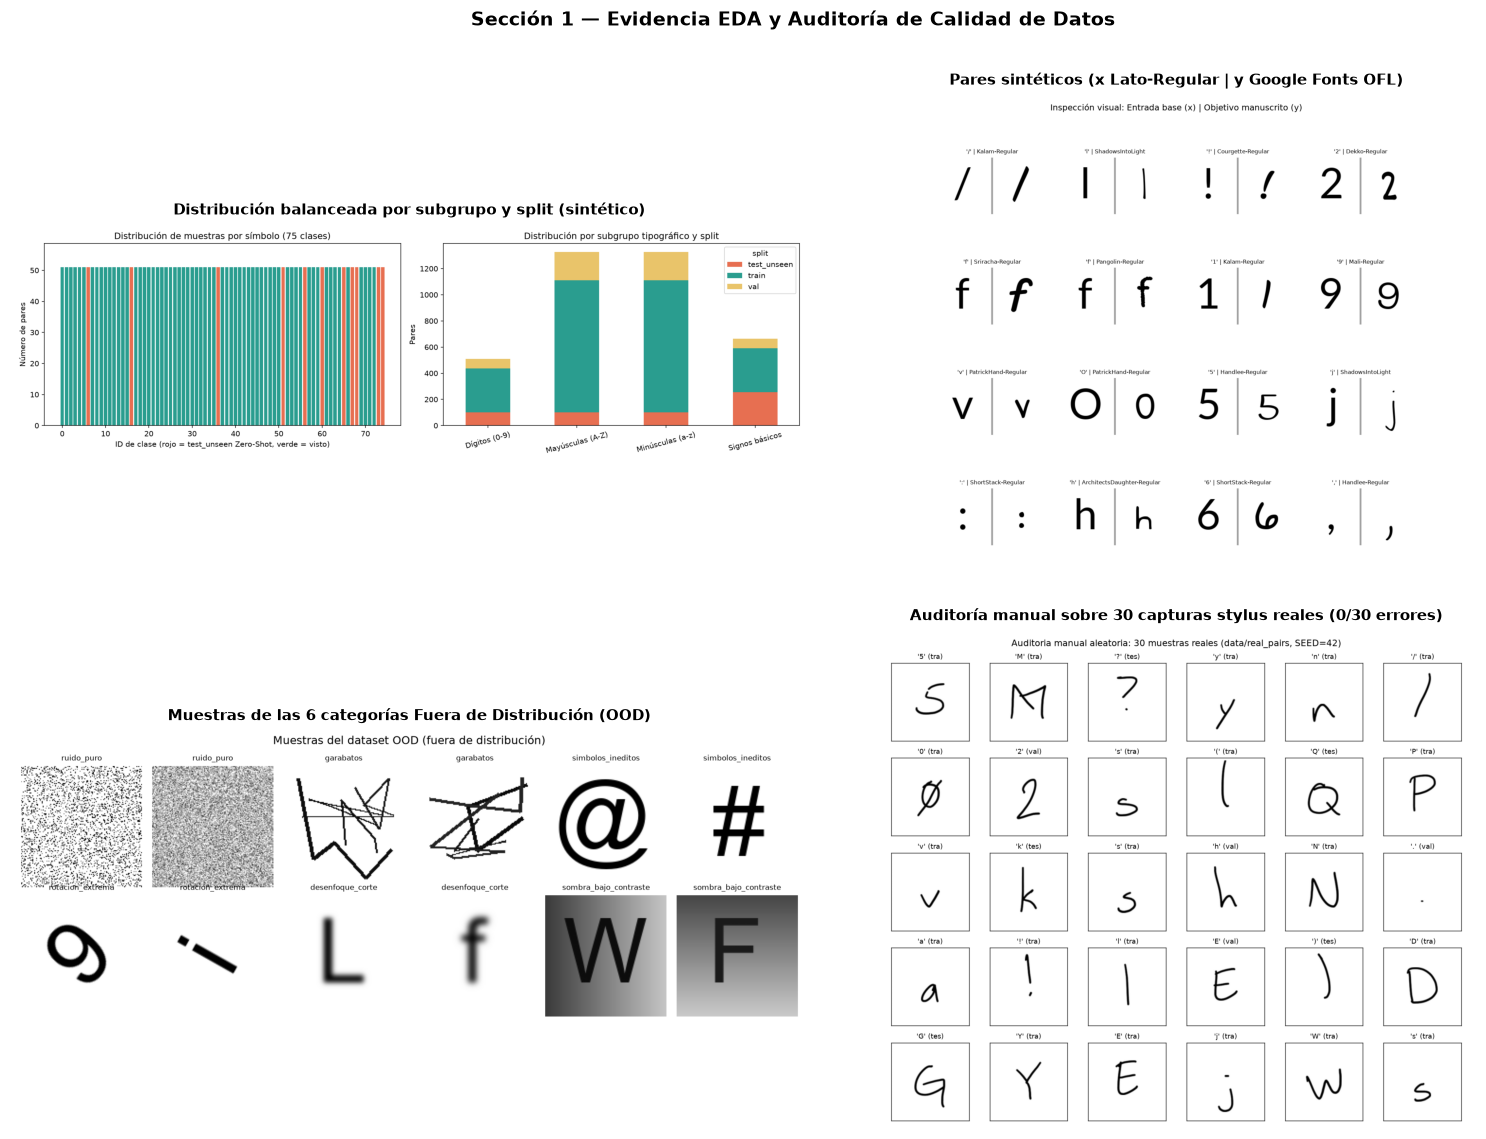

In [3]:
show_figure_grid(
    [
        ("docs/figuras/eda_distribucion_clases.png", "Distribución balanceada por subgrupo y split (sintético)"),
        ("docs/figuras/eda_sinteticos.png", "Pares sintéticos (x Lato-Regular | y Google Fonts OFL)"),
        ("docs/figuras/eda_ood.png", "Muestras de las 6 categorías Fuera de Distribución (OOD)"),
        ("docs/figuras/auditoria_calidad_real_30.png", "Auditoría manual sobre 30 capturas stylus reales (0/30 errores)"),
    ],
    ncols=2,
    figsize=(14.5, 10.2),
    suptitle="Sección 1 — Evidencia EDA y Auditoría de Calidad de Datos",
)

---
## 2. Arquitectura y Flujo Tensorial (`1×128×128`)

> **Fuente técnica detallada:** [`src/models/pix2pix.py`](../src/models/pix2pix.py) · [`src/models/style_unet.py`](../src/models/style_unet.py) · [`src/models/judges.py`](../src/models/judges.py)

El sistema opera sobre tensores en escala de grises `x ∈ [-1, 1]^(B×1×128×128)` con un diseño modular de cuatro componentes:

1. **Generador base `UNetGenerator` (Pix2Pix):** 7 bloques encoder (`128 → 64 → 32 → 16 → 8 → 4 → 2 → 1`) + 7 bloques decoder con *skip connections* (`1 → 2 → 4 → 8 → 16 → 32 → 64 → 128`, Dropout `0.5` en los 3 niveles más profundos) y salida `Tanh`. Entrenado con pérdida combinada adversarial + reconstrucción `L1 (λ_L1 = 100.0)`.
2. **Generador aditivo `StyleUNetGenerator` (`StyleEncoder` + `AdaIN2d`):** Desacopla explícitamente el **contenido** (`x`, fuente `Lato`) del **estilo caligráfico** ($K = 4$ glifos de referencia `[B, 4, 1, 128, 128]`). Su `StyleEncoder` omite `InstanceNorm` (siguiendo MUNIT/FUNIT) para preservar la densidad de tinta y el grosor de trazo fino del stylus, produciendo un vector `z_style ∈ R^128` que modula el bottleneck y los 6 bloques decoder mediante `AdaIN2d` (inicializado en identidad). Se entrena con `PatchGAN BCE + 100·L1 + 5·StyleConsistency + 15·InkDiff`.
3. **Discriminador condicional `PatchGANDiscriminator` (`70×70`):** Recibe el par concatenado `[x, y]` (`[B, 2, 128, 128]`) y produce un mapa de logits `14×14` con *one-sided label smoothing* (`0.9` real / `0.0` falso). Solo se usa durante entrenamiento.
4. **Doble Juez CNN congelado (`ResNet18Judge` y `EfficientNetB0Judge`):** Adaptados a 1 canal y 75 clases; exponen `extract_features(x)` (`512-d` en `ResNet-18`, `1280-d` en `EfficientNet-B0`) para calcular **Accuracy, Macro-F1, FID de dominio, Grad-CAM y filtro OOD**.

### Justificación arquitectónica frente a alternativas
| Alternativa evaluada | Evidencia / Criterio | Decisión adoptada |
| :--- | :--- | :--- |
| **`Pix2Pix` vs. `StyleUNet (AdaIN)`** | Experimento propio (`03` vs. `04`) | `Pix2Pix` sufre choque de grosor en trazos finos (`2.57 %` tinta) y degrada en *Zero-Shot* (`9.09–27.27 %`). `StyleUNet` desacopla estilo y contenido, alcanzando `89.06 %` Acc en `val` y **`72.73 %`** en *Zero-Shot*. |
| **`ResNet-18` vs. `EfficientNet-B0`** | Experimento propio (`02`, `robustez`) | `ResNet-18` logra mayor Accuracy (`87.67 %` vs. `85.07 %`), mejor separación OOD (`AUROC 0.9435` vs. `0.8856`) y menor latencia CPU (`4.69 ms` en ONNX). Se usa como juez en vivo y `EfficientNet-B0` como validación cruzada independiente. |
| **Descarte de Diffusion / ControlNet** | Restricción de latencia y hardware | Requieren GPU dedicada (>6 GB VRAM) y segundos por glifo (`<1 FPS` en CPU), incumpliendo el requisito de tiempo real (`≥10 FPS` en CPU). |
| **Descarte de CycleGAN** | Disponibilidad de pares exactos | Opera sin pares alineados ni pérdida `L1`; tiende a deformar topologías de símbolos inéditos. Con pares exactos `(Lato, manuscrito)`, las *skip connections* + `L1` preservan la estructura base. |

,Modelo,Rol,Entrada,Salida,Parámetros totales,Parámetros entrenables,Parámetros (M),Peso FP32 (MB),Nota técnica
0,UNetGenerator (Pix2Pix),Generador cGAN base,"(1, 1, 128, 128)","(1, 1, 128, 128)",41823425,41823425,41.82,159.54,"Salida Tanh [-1, 1]"
1,PatchGANDiscriminator (70×70),Discriminador (solo train),"(1, 1, 128, 128) + (1, 1, 128, 128)","(1, 1, 14, 14)",2764609,2764609,2.76,10.55,Logits 14×14 (70×70 RF)
2,StyleEncoder (submódulo),Extractor estilo sin IN,"(1, 4, 1, 128, 128)","(1, 128)",1787360,1787360,1.79,6.82,Vector z_style (128-d)
3,StyleUNetGenerator (total),Generador AdaIN + StyleEnc,"x:(1, 1, 128, 128), refs:(1, 4, 1, 128, 128)","(1, 1, 128, 128)",44184737,44184737,44.18,168.55,6 bloques AdaIN2d + Tanh
4,ResNet18Judge (75 clases),Juez principal + OOD + CAM,"(1, 1, 128, 128)","logits:(1, 75) | feats:(1, 512)",11208715,11208715,11.21,42.76,Embedding 512-d (FID)
5,EfficientNetB0Judge (75 clases),Juez secundario cruzado,"(1, 1, 128, 128)","logits:(1, 75) | feats:(1, 1280)",4103047,4103047,4.10,15.65,Embedding 1280-d (FID)



Flujo tensorial exacto de UNetGenerator (1×128×128):
  x(1, 1, 128, 128) -> d1(1, 64, 64, 64) -> d2(1, 128, 32, 32) -> d3(1, 256, 16, 16) -> d4(1, 512, 8, 8) -> d5(1, 512, 4, 4) -> d6(1, 512, 2, 2) -> bn(1, 512, 1, 1)
  -> u1(1, 1024, 2, 2) -> u2(1, 1024, 4, 4) -> u3(1, 1024, 8, 8) -> u4(1, 512, 16, 16) -> u5(1, 256, 32, 32) -> u6(1, 128, 64, 64) -> y_hat(1, 1, 128, 128)


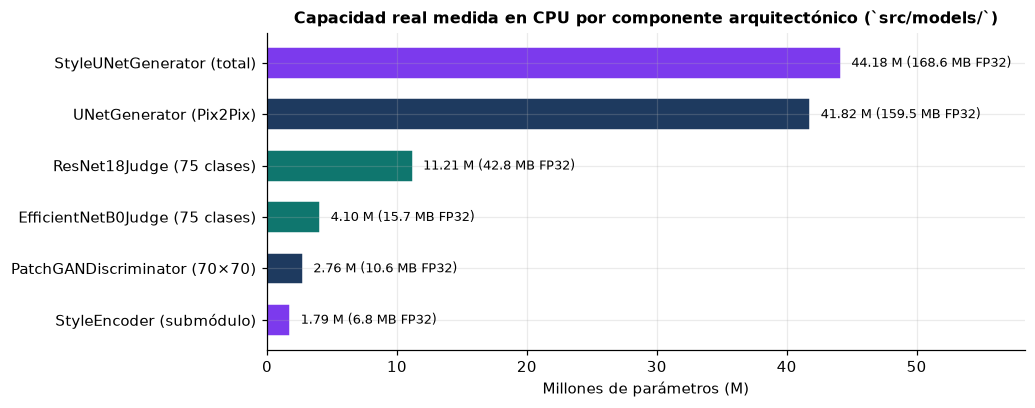

In [4]:
from src.models.judges import EfficientNetB0Judge, ResNet18Judge
from src.models.pix2pix import PatchGANDiscriminator, UNetGenerator
from src.models.style_unet import StyleEncoder, StyleUNetGenerator

# Instanciar modelos reales en CPU (pretrained=False para evitar descargas en ejecución offline)
models_spec = [
    ("UNetGenerator (Pix2Pix)", UNetGenerator(in_channels=1, out_channels=1, base_features=64), "Generador cGAN base"),
    ("PatchGANDiscriminator (70×70)", PatchGANDiscriminator(in_channels=2, base_features=64), "Discriminador (solo train)"),
    ("StyleEncoder (submódulo)", StyleEncoder(in_channels=1, style_dim=128, base_features=32), "Extractor estilo sin IN"),
    ("StyleUNetGenerator (total)", StyleUNetGenerator(in_channels=1, out_channels=1, base_features=64, style_dim=128), "Generador AdaIN + StyleEnc"),
    ("ResNet18Judge (75 clases)", ResNet18Judge(num_classes=75, pretrained=False), "Juez principal + OOD + CAM"),
    ("EfficientNetB0Judge (75 clases)", EfficientNetB0Judge(num_classes=75, pretrained=False), "Juez secundario cruzado"),
]

x_dummy = torch.randn(1, 1, 128, 128)
y_dummy = torch.randn(1, 1, 128, 128)
refs_dummy = torch.randn(1, 4, 1, 128, 128)

arch_rows = []
with torch.no_grad():
    for name, model, role in models_spec:
        model.eval()
        total_p = sum(p.numel() for p in model.parameters())
        train_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
        fp32_mb = total_p * 4 / (1024 ** 2)

        if isinstance(model, UNetGenerator):
            out = model(x_dummy)
            in_shape = str(tuple(x_dummy.shape))
            out_shape = str(tuple(out.shape))
            extra = "Salida Tanh [-1, 1]"
        elif isinstance(model, PatchGANDiscriminator):
            out = model(x_dummy, y_dummy)
            in_shape = f"{tuple(x_dummy.shape)} + {tuple(y_dummy.shape)}"
            out_shape = str(tuple(out.shape))
            extra = "Logits 14×14 (70×70 RF)"
        elif isinstance(model, StyleEncoder):
            out = model(refs_dummy)
            in_shape = str(tuple(refs_dummy.shape))
            out_shape = str(tuple(out.shape))
            extra = "Vector z_style (128-d)"
        elif isinstance(model, StyleUNetGenerator):
            out = model(x_dummy, style_refs=refs_dummy)
            in_shape = f"x:{tuple(x_dummy.shape)}, refs:{tuple(refs_dummy.shape)}"
            out_shape = str(tuple(out.shape))
            extra = "6 bloques AdaIN2d + Tanh"
        else:
            logits = model(x_dummy)
            feats = model.extract_features(x_dummy)
            in_shape = str(tuple(x_dummy.shape))
            out_shape = f"logits:{tuple(logits.shape)} | feats:{tuple(feats.shape)}"
            extra = f"Embedding {model.feature_dim}-d (FID)"

        arch_rows.append(
            {
                "Modelo": name,
                "Rol": role,
                "Entrada": in_shape,
                "Salida": out_shape,
                "Parámetros totales": total_p,
                "Parámetros entrenables": train_p,
                "Parámetros (M)": round(total_p / 1e6, 2),
                "Peso FP32 (MB)": round(fp32_mb, 2),
                "Nota técnica": extra,
            }
        )

df_arch = pd.DataFrame(arch_rows)
display(df_arch)

# Trazado tensorial explícito del encoder-decoder de UNetGenerator
gen = models_spec[0][1]
with torch.no_grad():
    d1 = gen.down1(x_dummy)
    d2 = gen.down2(d1)
    d3 = gen.down3(d2)
    d4 = gen.down4(d3)
    d5 = gen.down5(d4)
    d6 = gen.down6(d5)
    bn = gen.down7(d6)
    u1 = gen.up1(bn, d6)
    u2 = gen.up2(u1, d5)
    u3 = gen.up3(u2, d4)
    u4 = gen.up4(u3, d3)
    u5 = gen.up5(u4, d2)
    u6 = gen.up6(u5, d1)
    y_out = gen.up7(u6)

print("\nFlujo tensorial exacto de UNetGenerator (1×128×128):")
print(
    f"  x{tuple(x_dummy.shape)} -> d1{tuple(d1.shape)} -> d2{tuple(d2.shape)} -> d3{tuple(d3.shape)} -> "
    f"d4{tuple(d4.shape)} -> d5{tuple(d5.shape)} -> d6{tuple(d6.shape)} -> bn{tuple(bn.shape)}"
)
print(
    f"  -> u1{tuple(u1.shape)} -> u2{tuple(u2.shape)} -> u3{tuple(u3.shape)} -> u4{tuple(u4.shape)} -> "
    f"u5{tuple(u5.shape)} -> u6{tuple(u6.shape)} -> y_hat{tuple(y_out.shape)}"
)

# Gráfica comparativa de número de parámetros (M)
fig, ax = plt.subplots(figsize=(9.5, 3.8))
plot_df = df_arch.sort_values("Parámetros (M)", ascending=True)
colors = [PALETTE["purple"] if "Style" in m else (PALETTE["teal"] if "Judge" in m else PALETTE["navy"]) for m in plot_df["Modelo"]]
bars = ax.barh(plot_df["Modelo"], plot_df["Parámetros (M)"], color=colors, edgecolor="white", height=0.62)
for bar, val, mb in zip(bars, plot_df["Parámetros (M)"], plot_df["Peso FP32 (MB)"]):
    ax.text(val + 0.8, bar.get_y() + bar.get_height() / 2, f"{val:.2f} M ({mb:.1f} MB FP32)", va="center", fontsize=8.8)
ax.set_xlabel("Millones de parámetros (M)")
ax.set_title("Capacidad real medida en CPU por componente arquitectónico (`src/models/`)")
ax.set_xlim(0, plot_df["Parámetros (M)"].max() * 1.32)
plt.tight_layout()
plt.show()

---
## 3. Evolución Experimental y Comparativa Unificada

> **Fuente técnica detallada:** [`02_colab_training.ipynb`](02_colab_training.ipynb) · [`03_colab_finetuning.ipynb`](03_colab_finetuning.ipynb) · [`04_colab_style_encoder.ipynb`](04_colab_style_encoder.ipynb) · [`docs/bitacora_iteraciones.md`](../docs/bitacora_iteraciones.md)

El desarrollo siguió una progresión experimental documentada en `notebooks/02`, `03`, `04` y `docs/bitacora_iteraciones.md`:

1. **Etapa A — Evaluadores CNN y Preentrenamiento Sintético (`02_colab_training.ipynb`):** Se entrenaron `ResNet-18` (`30` ep, mejor ep. `23`) y `EfficientNet-B0` (`22` ep con *early stopping*, mejor ep. `15`) sobre `synthetic_pairs` (`judge_split`), y luego `pix2pix_pretrained` (`60` ep, mejor ep. `11`). En validación sintética (`val`), `pix2pix_pretrained` alcanzó **`71.88 %` Acc** (`ResNet-18`, FID `133.24`) y **`45.45 % / 54.55 %`** en *Zero-Shot* (`test_unseen`).
2. **Etapa B — Choque de grosor de trazo sobre stylus real (`03_colab_finetuning.ipynb`):** Al transferir `Pix2Pix` a los **300 trazos personales con stylus**, apareció un hallazgo decisivo: la densidad media de tinta del stylus es **`2.57 %`**, mucho más delgada que las 17 fuentes sintéticas. Como en `Pix2Pix` el estilo está distribuido por todos los pesos de la U-Net:
   - `pix2pix_scratch` (`150` ep) superó a `pix2pix_finetuned` (`100` ep) en `val` (**`75.00 %` Acc / FID `94.87`** vs. `62.50 %` Acc / FID `121.14`).
   - Reiniciar el discriminador y seleccionar checkpoint únicamente por mínimo `val_l1` provocó colapso hacia lienzos casi en blanco (`val_l1 = 0.0455`).
   - Peor aún, **ambas variantes de Pix2Pix degradaron severamente en *Zero-Shot*** (`test_unseen`): `pix2pix_finetuned` cayó hasta **`9.09 %`** (`ResNet-18`, FID `499.83`) y `pix2pix_scratch` a **`27.27 %` / `9.09 %`** (`FID 469.96`).
3. **Etapa C — Solución aditiva con `StyleUNet` (`StyleEncoder` + `AdaIN`, `04_colab_style_encoder.ipynb`):** Desacoplando contenido y estilo ($K=4$ referencias reales en `StyleEncoder` sin `InstanceNorm` + aumento morfológico emparejado de grosor + pérdida `InkDiff`):
   - **Sin *fine-tuning* (`style_unet_fewshot`, 0 épocas, 4 referencias reales):** ya superó a todas las variantes de Pix2Pix tanto en `val` (**`84.38 %`** Acc) como en *Zero-Shot* (**`54.55 %`** Acc, FID `307.42`).
   - **Con *fine-tuning* ligero (`style_unet_finetuned`, mejor época 4, `StyleEncoder` congelado):** **igualó el techo humano real en `val` (`89.06 %` Acc / `85.94 %` Macro-F1)** y elevó *Zero-Shot* hasta **`72.73 %` Acc / Macro-F1** (**`+63.64 pp`** sobre `pix2pix_finetuned`, **`+45.46 pp`** sobre `pix2pix_pretrained`, reduciendo el FID de dominio de **`499.83 → 302.42`**).

> **Nota estadística:** `test_unseen` tiene exactamente **11 clases** (~`9.09 pp` por clase en Accuracy). En `synthetic_pairs/test_unseen`, el techo global `reference_y` (`98.22 %`) incluye 462/561 muestras de `judge_split=train`, mientras que el subconjunto estricto `judge_split=val` (`n=99`) obtiene `89.90 %`, consistente con `real_pairs/test_unseen` (`86.36 %`, 0 % traslape).

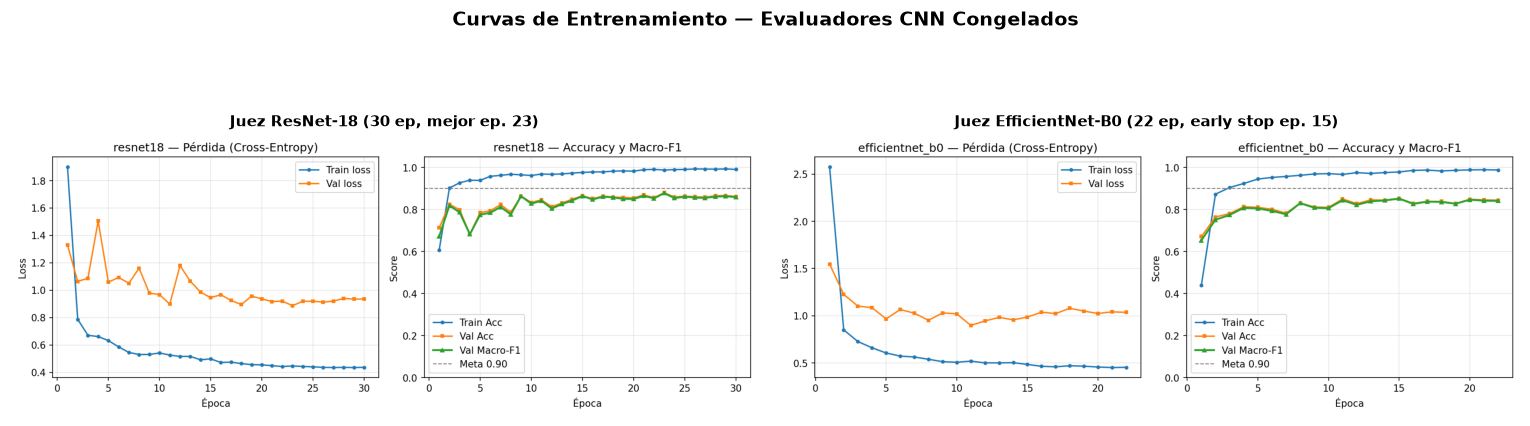

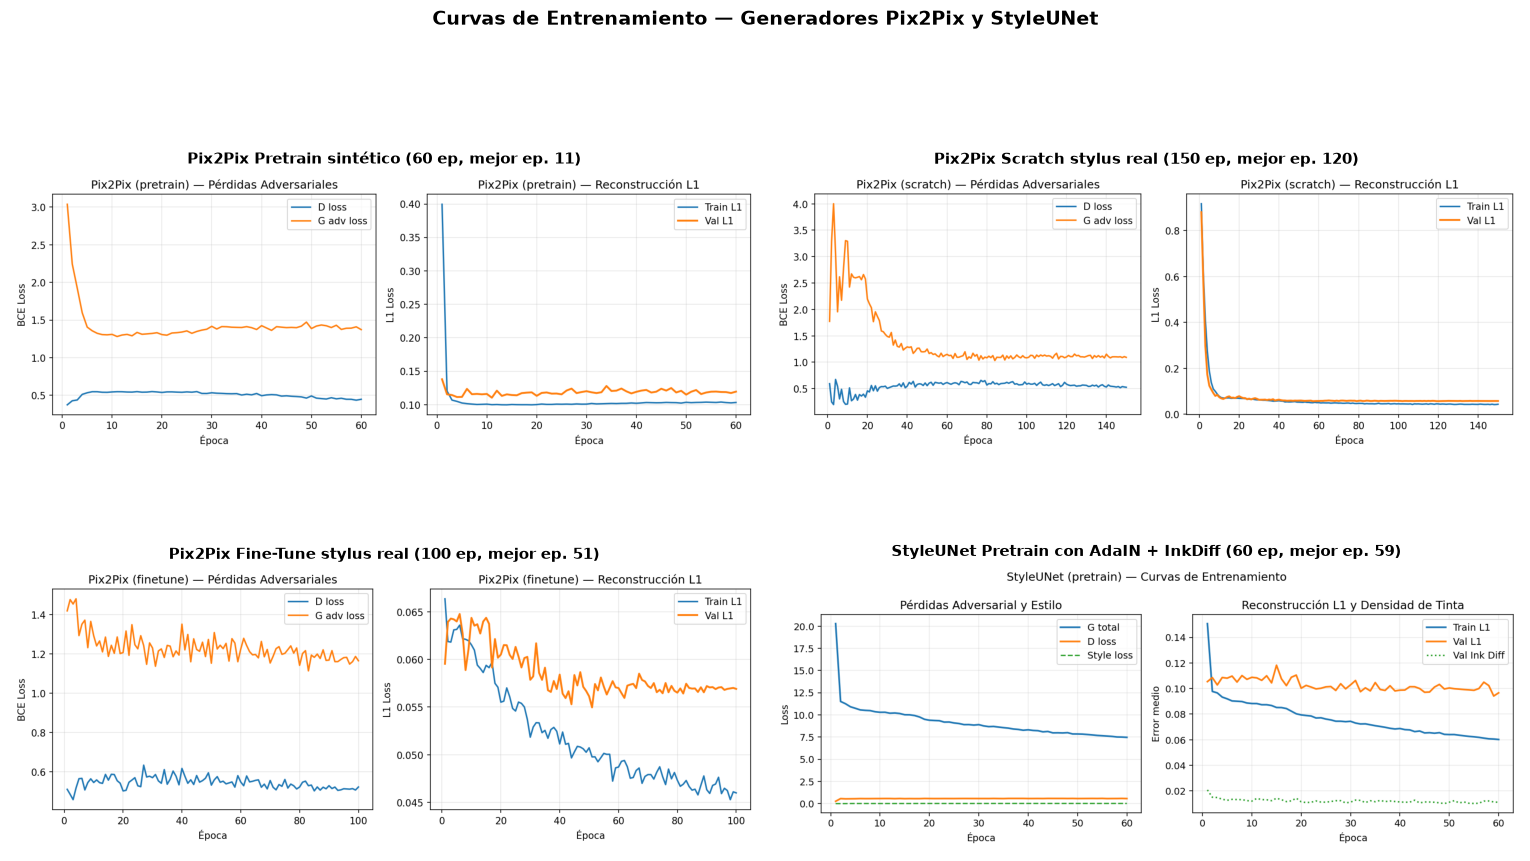

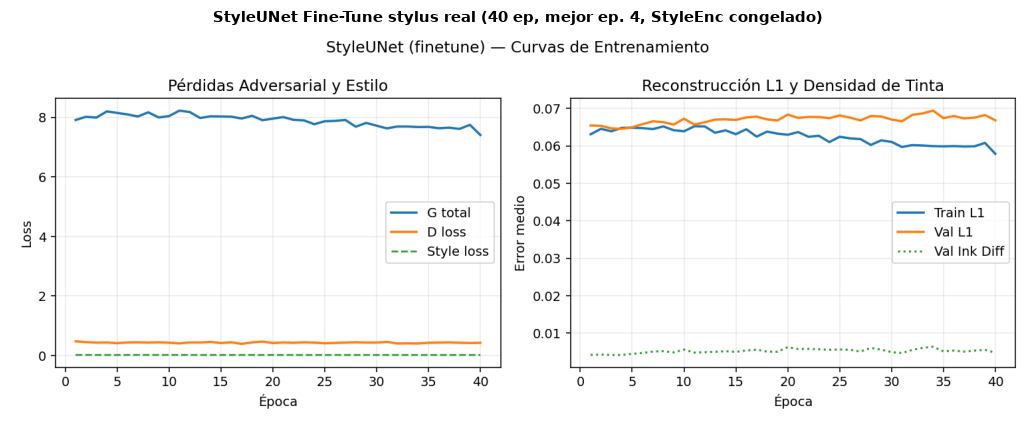

In [5]:
show_figure_grid(
    [
        ("docs/figuras/train_judge_resnet18.png", "Juez ResNet-18 (30 ep, mejor ep. 23)"),
        ("docs/figuras/train_judge_efficientnet_b0.png", "Juez EfficientNet-B0 (22 ep, early stop ep. 15)"),
    ],
    ncols=2,
    figsize=(14.0, 4.4),
    suptitle="Curvas de Entrenamiento — Evaluadores CNN Congelados",
)

show_figure_grid(
    [
        ("docs/figuras/train_pix2pix_pretrain.png", "Pix2Pix Pretrain sintético (60 ep, mejor ep. 11)"),
        ("docs/figuras/train_pix2pix_scratch.png", "Pix2Pix Scratch stylus real (150 ep, mejor ep. 120)"),
        ("docs/figuras/train_pix2pix_finetune.png", "Pix2Pix Fine-Tune stylus real (100 ep, mejor ep. 51)"),
        ("docs/figuras/train_style_unet_pretrain.png", "StyleUNet Pretrain con AdaIN + InkDiff (60 ep, mejor ep. 59)"),
    ],
    ncols=2,
    figsize=(14.0, 8.6),
    suptitle="Curvas de Entrenamiento — Generadores Pix2Pix y StyleUNet",
)

show_figure_grid(
    [
        ("docs/figuras/train_style_unet_finetune.png", "StyleUNet Fine-Tune stylus real (40 ep, mejor ep. 4, StyleEnc congelado)"),
    ],
    ncols=1,
    figsize=(9.5, 4.3),
)

#### A) Dominio Sintético Multi-Fuente (`data/synthetic_pairs/`, `metrics_pretrain.json`)

,Split,Modelo / Fuente,Acc R18 (%),Acc EffNet (%),Macro-F1 R18 (%),Macro-F1 EffNet (%),L1 media,FID dominio (R18)
0,"val (64 vistas, 3 fuentes inéditas)",Referencia y (techo),87.67,85.07,87.58,85.30,NaN,0.00
1,"val (64 vistas, 3 fuentes inéditas)",pix2pix_pretrained,71.88,68.75,67.45,64.58,0.11039,133.24
2,test_unseen (11 Zero-Shot)*,Referencia y (techo),98.22,97.68,98.99,98.61,NaN,0.00
3,test_unseen (11 Zero-Shot)*,pix2pix_pretrained,45.45,54.55,45.45,50.00,0.09939,358.22


#### B) Dominio Personal Real con Stylus (`data/real_pairs/`, 300 muestras — `Pix2Pix` vs. `StyleUNet`)

,Split,Modelo,Acc R18 (%),Acc EffNet (%),Macro-F1 R18 (%),Macro-F1 EffNet (%),L1 media,FID (R18)
0,val (64 vistas),reference_y (techo),89.06,84.38,86.20,81.25,NaN,0.00
1,val (64 vistas),pix2pix_pretrained,71.88,71.88,67.45,67.97,0.0947,145.25
2,val (64 vistas),pix2pix_scratch,75.00,67.19,69.27,59.64,0.0570,94.87
3,val (64 vistas),pix2pix_finetuned,62.50,56.25,56.38,47.50,0.0550,121.14
4,val (64 vistas),style_unet_fewshot,84.38,73.44,80.99,69.79,0.0639,141.47
5,val (64 vistas),style_unet_finetuned,89.06,79.69,85.94,74.95,0.0646,126.18
6,test_unseen (11 Zero-Shot),reference_y (techo),86.36,81.82,85.28,78.79,NaN,0.00
7,test_unseen (11 Zero-Shot),pix2pix_pretrained,27.27,45.45,27.27,42.42,0.0981,407.37
8,test_unseen (11 Zero-Shot),pix2pix_scratch,27.27,9.09,27.27,3.03,0.0691,469.96
9,test_unseen (11 Zero-Shot),pix2pix_finetuned,9.09,27.27,9.09,21.82,0.0667,499.83


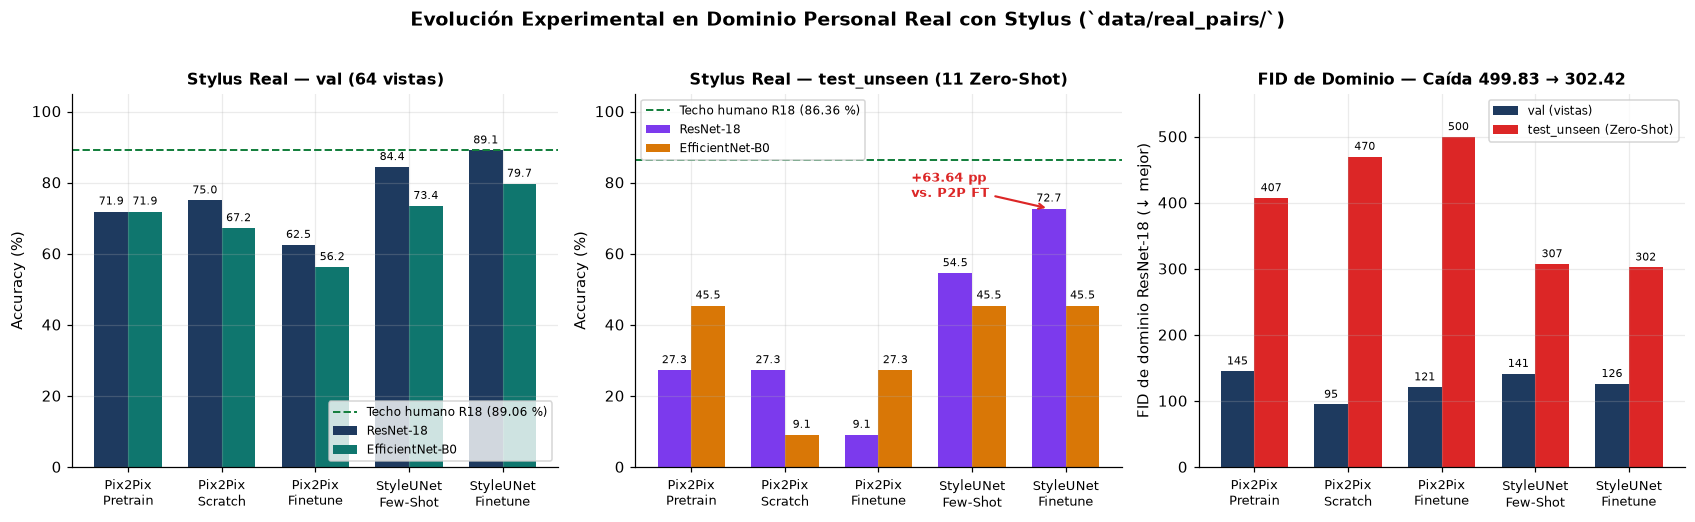

In [6]:
# 1) Tabla A — Dominio sintético multi-fuente (leída dinámicamente de results/eval/metrics_pretrain.json)
metrics_pretrain = json.loads((ROOT_DIR / "results" / "eval" / "metrics_pretrain.json").read_text(encoding="utf-8"))

syn_rows = []
for split_key, split_label in [
    ("val", "val (64 vistas, 3 fuentes inéditas)"),
    ("test_unseen", "test_unseen (11 Zero-Shot)*"),
]:
    sources = metrics_pretrain["splits"][split_key]["sources"]
    for src_key, model_label in [
        ("reference_y", "Referencia y (techo)"),
        ("pretrained", "pix2pix_pretrained"),
    ]:
        src = sources[src_key]
        r18 = src["judges"]["resnet18"]
        eff = src["judges"]["efficientnet_b0"]
        syn_rows.append(
            {
                "Split": split_label,
                "Modelo / Fuente": model_label,
                "Acc R18 (%)": round(r18["accuracy"] * 100, 2),
                "Acc EffNet (%)": round(eff["accuracy"] * 100, 2),
                "Macro-F1 R18 (%)": round(r18["macro_f1"] * 100, 2),
                "Macro-F1 EffNet (%)": round(eff["macro_f1"] * 100, 2),
                "L1 media": src["mean_l1"],
                "FID dominio (R18)": 0.0 if src_key == "reference_y" else round(r18["domain_fid"], 2),
            }
        )
df_syn = pd.DataFrame(syn_rows)

# 2) Tabla B — Dominio personal real con stylus (fuente oficial: README.md / MODEL_CARD.md / notebooks 03 y 04)
real_rows = [
    # val (64 vistas)
    {"Split": "val (64 vistas)", "Modelo": "reference_y (techo)", "Acc R18 (%)": 89.06, "Acc EffNet (%)": 84.38, "Macro-F1 R18 (%)": 86.20, "Macro-F1 EffNet (%)": 81.25, "L1 media": np.nan, "FID (R18)": 0.00},
    {"Split": "val (64 vistas)", "Modelo": "pix2pix_pretrained", "Acc R18 (%)": 71.88, "Acc EffNet (%)": 71.88, "Macro-F1 R18 (%)": 67.45, "Macro-F1 EffNet (%)": 67.97, "L1 media": 0.0947, "FID (R18)": 145.25},
    {"Split": "val (64 vistas)", "Modelo": "pix2pix_scratch", "Acc R18 (%)": 75.00, "Acc EffNet (%)": 67.19, "Macro-F1 R18 (%)": 69.27, "Macro-F1 EffNet (%)": 59.64, "L1 media": 0.0570, "FID (R18)": 94.87},
    {"Split": "val (64 vistas)", "Modelo": "pix2pix_finetuned", "Acc R18 (%)": 62.50, "Acc EffNet (%)": 56.25, "Macro-F1 R18 (%)": 56.38, "Macro-F1 EffNet (%)": 47.50, "L1 media": 0.0550, "FID (R18)": 121.14},
    {"Split": "val (64 vistas)", "Modelo": "style_unet_fewshot", "Acc R18 (%)": 84.38, "Acc EffNet (%)": 73.44, "Macro-F1 R18 (%)": 80.99, "Macro-F1 EffNet (%)": 69.79, "L1 media": 0.0639, "FID (R18)": 141.47},
    {"Split": "val (64 vistas)", "Modelo": "style_unet_finetuned", "Acc R18 (%)": 89.06, "Acc EffNet (%)": 79.69, "Macro-F1 R18 (%)": 85.94, "Macro-F1 EffNet (%)": 74.95, "L1 media": 0.0646, "FID (R18)": 126.18},
    # test_unseen (11 Zero-Shot, n=44)
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "reference_y (techo)", "Acc R18 (%)": 86.36, "Acc EffNet (%)": 81.82, "Macro-F1 R18 (%)": 85.28, "Macro-F1 EffNet (%)": 78.79, "L1 media": np.nan, "FID (R18)": 0.00},
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "pix2pix_pretrained", "Acc R18 (%)": 27.27, "Acc EffNet (%)": 45.45, "Macro-F1 R18 (%)": 27.27, "Macro-F1 EffNet (%)": 42.42, "L1 media": 0.0981, "FID (R18)": 407.37},
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "pix2pix_scratch", "Acc R18 (%)": 27.27, "Acc EffNet (%)": 9.09, "Macro-F1 R18 (%)": 27.27, "Macro-F1 EffNet (%)": 3.03, "L1 media": 0.0691, "FID (R18)": 469.96},
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "pix2pix_finetuned", "Acc R18 (%)": 9.09, "Acc EffNet (%)": 27.27, "Macro-F1 R18 (%)": 9.09, "Macro-F1 EffNet (%)": 21.82, "L1 media": 0.0667, "FID (R18)": 499.83},
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "style_unet_fewshot", "Acc R18 (%)": 54.55, "Acc EffNet (%)": 45.45, "Macro-F1 R18 (%)": 54.55, "Macro-F1 EffNet (%)": 42.42, "L1 media": 0.0676, "FID (R18)": 307.42},
    {"Split": "test_unseen (11 Zero-Shot)", "Modelo": "style_unet_finetuned", "Acc R18 (%)": 72.73, "Acc EffNet (%)": 45.45, "Macro-F1 R18 (%)": 72.73, "Macro-F1 EffNet (%)": 42.42, "L1 media": 0.0728, "FID (R18)": 302.42},
]
df_real = pd.DataFrame(real_rows)

display(Markdown("#### A) Dominio Sintético Multi-Fuente (`data/synthetic_pairs/`, `metrics_pretrain.json`)"))
display(df_syn)

display(Markdown("#### B) Dominio Personal Real con Stylus (`data/real_pairs/`, 300 muestras — `Pix2Pix` vs. `StyleUNet`)"))
display(df_real)

# Gráfica comparativa unificada generada en vivo (3 paneles)
gen_models = ["pix2pix_pretrained", "pix2pix_scratch", "pix2pix_finetuned", "style_unet_fewshot", "style_unet_finetuned"]
short_labels = ["Pix2Pix\nPretrain", "Pix2Pix\nScratch", "Pix2Pix\nFinetune", "StyleUNet\nFew-Shot", "StyleUNet\nFinetune"]

val_gen = df_real[(df_real["Split"] == "val (64 vistas)") & (df_real["Modelo"].isin(gen_models))].set_index("Modelo").loc[gen_models]
uns_gen = df_real[(df_real["Split"] == "test_unseen (11 Zero-Shot)") & (df_real["Modelo"].isin(gen_models))].set_index("Modelo").loc[gen_models]

fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6))
x = np.arange(len(gen_models))
w = 0.36

# Panel 1: Accuracy en val (stylus real)
b1 = axes[0].bar(x - w / 2, val_gen["Acc R18 (%)"], w, label="ResNet-18", color=PALETTE["navy"])
b2 = axes[0].bar(x + w / 2, val_gen["Acc EffNet (%)"], w, label="EfficientNet-B0", color=PALETTE["teal"])
axes[0].axhline(89.06, color=PALETTE["green"], linestyle="--", linewidth=1.3, label="Techo humano R18 (89.06 %)")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{b.get_height():.1f}", ha="center", va="bottom", fontsize=7.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(short_labels, fontsize=8.3)
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Stylus Real — val (64 vistas)")
axes[0].legend(fontsize=7.8, loc="lower right")

# Panel 2: Accuracy en test_unseen (Zero-Shot)
b3 = axes[1].bar(x - w / 2, uns_gen["Acc R18 (%)"], w, label="ResNet-18", color=PALETTE["purple"])
b4 = axes[1].bar(x + w / 2, uns_gen["Acc EffNet (%)"], w, label="EfficientNet-B0", color=PALETTE["amber"])
axes[1].axhline(86.36, color=PALETTE["green"], linestyle="--", linewidth=1.3, label="Techo humano R18 (86.36 %)")
for bars in (b3, b4):
    for b in bars:
        axes[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{b.get_height():.1f}", ha="center", va="bottom", fontsize=7.5)
axes[1].annotate(
    "+63.64 pp\nvs. P2P FT",
    xy=(4 - w / 2, 72.73),
    xytext=(2.35, 76),
    arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.4),
    fontsize=8.3,
    fontweight="bold",
    color=PALETTE["coral"],
)
axes[1].set_xticks(x)
axes[1].set_xticklabels(short_labels, fontsize=8.3)
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Stylus Real — test_unseen (11 Zero-Shot)")
axes[1].legend(fontsize=7.8, loc="upper left")

# Panel 3: FID de dominio (menor es mejor)
b5 = axes[2].bar(x - w / 2, val_gen["FID (R18)"], w, label="val (vistas)", color=PALETTE["navy"])
b6 = axes[2].bar(x + w / 2, uns_gen["FID (R18)"], w, label="test_unseen (Zero-Shot)", color=PALETTE["coral"])
for bars in (b5, b6):
    for b in bars:
        axes[2].text(b.get_x() + b.get_width() / 2, b.get_height() + 6, f"{b.get_height():.0f}", ha="center", va="bottom", fontsize=7.5)
axes[2].set_xticks(x)
axes[2].set_xticklabels(short_labels, fontsize=8.3)
axes[2].set_ylim(0, 565)
axes[2].set_ylabel("FID de dominio ResNet-18 (↓ mejor)")
axes[2].set_title("FID de Dominio — Caída 499.83 → 302.42")
axes[2].legend(fontsize=8, loc="upper right")

fig.suptitle("Evolución Experimental en Dominio Personal Real con Stylus (`data/real_pairs/`)", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

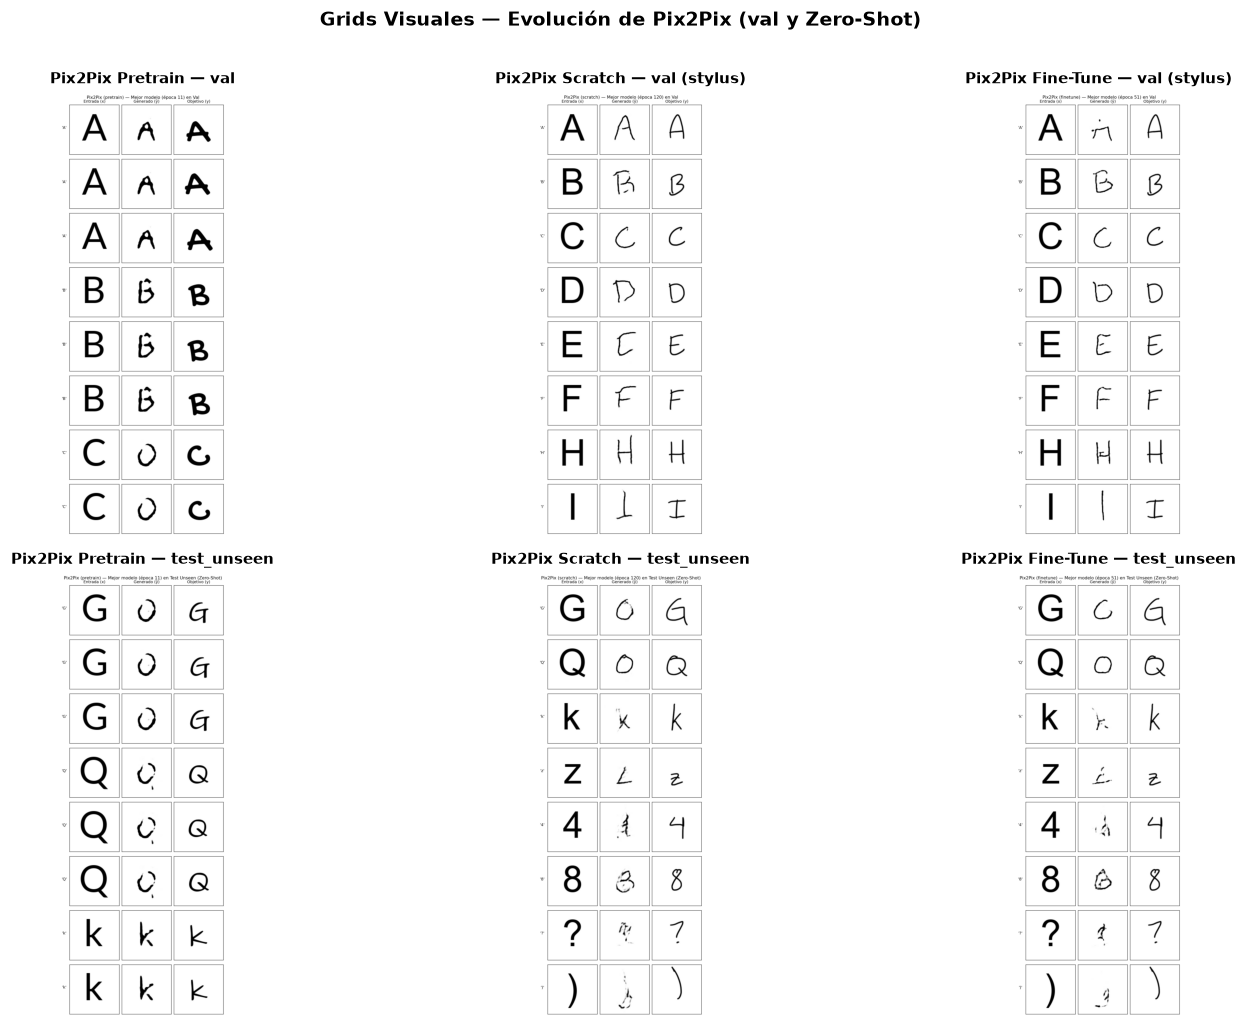

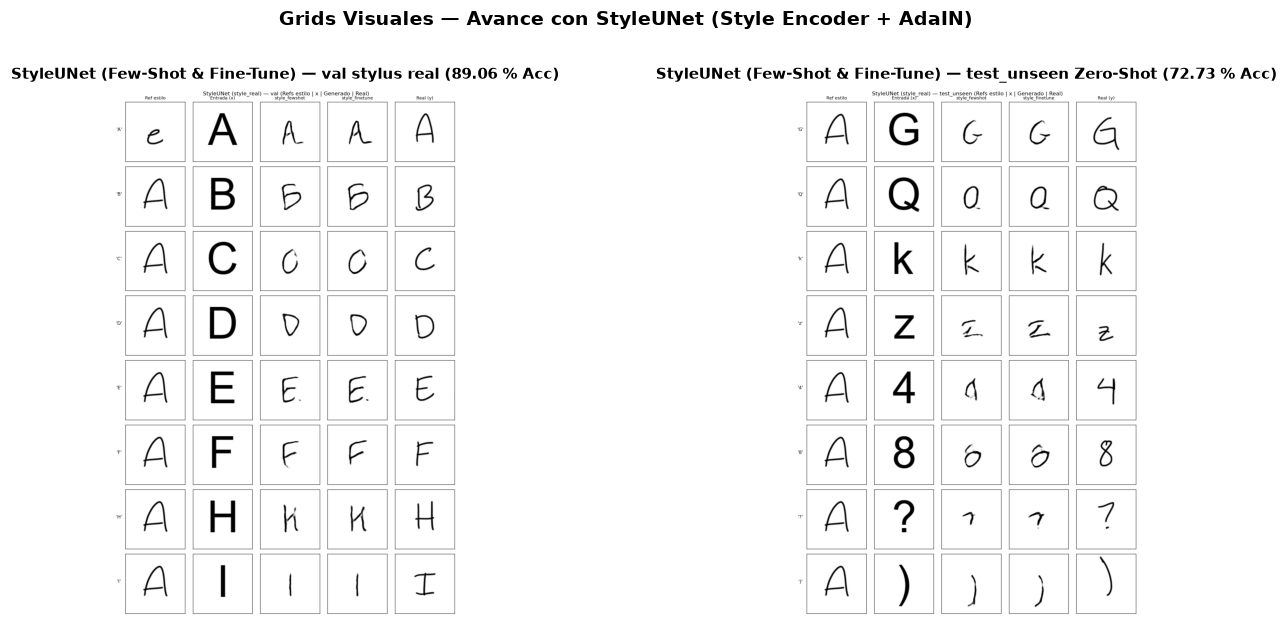

In [7]:
show_figure_grid(
    [
        ("docs/figuras/pix2pix_pretrain_val_grid.png", "Pix2Pix Pretrain — val"),
        ("docs/figuras/pix2pix_scratch_val_grid.png", "Pix2Pix Scratch — val (stylus)"),
        ("docs/figuras/pix2pix_finetune_val_grid.png", "Pix2Pix Fine-Tune — val (stylus)"),
        ("docs/figuras/pix2pix_pretrain_unseen_grid.png", "Pix2Pix Pretrain — test_unseen"),
        ("docs/figuras/pix2pix_scratch_unseen_grid.png", "Pix2Pix Scratch — test_unseen"),
        ("docs/figuras/pix2pix_finetune_unseen_grid.png", "Pix2Pix Fine-Tune — test_unseen"),
    ],
    ncols=3,
    figsize=(15.5, 9.2),
    suptitle="Grids Visuales — Evolución de Pix2Pix (val y Zero-Shot)",
)

show_figure_grid(
    [
        ("docs/figuras/style_eval_style_real_val.png", "StyleUNet (Few-Shot & Fine-Tune) — val stylus real (89.06 % Acc)"),
        ("docs/figuras/style_eval_style_real_test_unseen.png", "StyleUNet (Few-Shot & Fine-Tune) — test_unseen Zero-Shot (72.73 % Acc)"),
    ],
    ncols=2,
    figsize=(15.0, 5.6),
    suptitle="Grids Visuales — Avance con StyleUNet (Style Encoder + AdaIN)",
)

---
## 4. Auditoría por Subgrupos y Análisis de Errores

> **Fuente técnica detallada:** [`eval/auditoria_subgrupos.ipynb`](../eval/auditoria_subgrupos.ipynb) · [`eval/evaluate_models.py`](../eval/evaluate_models.py)

Evaluar únicamente la precisión global oculta disparidades estructurales entre tipos de glifos. En `eval/auditoria_subgrupos.ipynb` y `eval/evaluate_models.py` auditamos el modelo preentrenado (`pix2pix_pretrained`) desglosado en los 4 subgrupos tipográficos y categorizamos los **`468` errores totales** acumulados en `val` + `test_unseen`:

- **Brecha crítica entre subgrupos (`val`, juez `ResNet-18`):** **`Mayúsculas (A–Z)` alcanza `77.78 %` Macro-F1** (`77.8 %`), mientras **`Signos` cae a `45.83 %`** (`45.8 %`) — una brecha de **`31.95 pp`**. La razón física es directa: signos como `:`, `!`, `(` o `,` ocupan muy poca área de tinta negra, aportando un gradiente L1 reducido frente a caracteres densos.
- **Taxonomía de los `468` errores:** La mayoría (`306`, `65.4 %`) corresponde a **artefactos *Zero-Shot*** en los 6 caracteres inéditos complejos (`4, Q, 8, ), G, &` — aunque `?, k, +, ;, z` alcanzan `100 %` de acierto), seguida de trazos ambiguos (`54`), confusiones morfológicamente similares (`54`), confusión estructural de forma (`27`), confusión mayúsculas/minúsculas (`18`) y signos delgados (`9`).

Brecha Macro-F1 verificada en val (ResNet-18): Mayúsculas (A-Z) vs. Signos = 31.95 pp | Total errores auditados: 468


#### Desglose por subgrupo en `val` (juez `ResNet-18`, `reference_y` vs. `pix2pix_pretrained`)

,source,subgroup,n_samples,n_classes,accuracy,macro_f1,mean_conf,pass_070_pct,mean_l1
0,pretrained,Mayúsculas (A-Z),216,24,79.17,77.78,0.7397,66.67,0.1217
1,pretrained,Minúsculas (a-z),216,24,75.00,72.22,0.6979,58.33,0.1182
2,pretrained,Dígitos (0-9),72,8,62.50,62.50,0.6991,62.50,0.1147
3,pretrained,Signos,72,8,50.00,45.83,0.6834,50.00,0.0488
4,reference_y,Signos,72,8,95.83,97.50,0.9222,93.06,NaN
5,reference_y,Minúsculas (a-z),216,24,91.67,94.25,0.8337,80.56,NaN
6,reference_y,Mayúsculas (A-Z),216,24,82.41,88.39,0.8456,83.33,NaN
7,reference_y,Dígitos (0-9),72,8,83.33,86.34,0.7485,66.67,NaN


#### 12 peores caracteres (`val` + `test_unseen`) y desempeño individual de los 11 símbolos Zero-Shot

,split,subgroup,true_char,n,acc_pct,mean_conf,mean_l1,top_pred
0,val,Signos,(,9,0.0,0.128,0.1133,T
1,val,Mayúsculas (A-Z),R,9,0.0,0.152,0.1568,f
2,test_unseen,Signos,&,51,0.0,0.187,0.1331,!
3,test_unseen,Mayúsculas (A-Z),G,51,0.0,0.191,0.1363,O
4,test_unseen,Signos,),51,0.0,0.222,0.0745,!
5,val,Minúsculas (a-z),d,9,0.0,0.238,0.1156,U
6,test_unseen,Dígitos (0-9),8,51,0.0,0.244,0.1303,S
7,val,Mayúsculas (A-Z),C,9,0.0,0.271,0.1214,O
8,test_unseen,Mayúsculas (A-Z),Q,51,0.0,0.291,0.1498,U
9,val,Mayúsculas (A-Z),O,9,0.0,0.293,0.1201,U


,split,subgroup,true_char,n,acc_pct,mean_conf,mean_l1,top_pred
0,test_unseen,Signos,?,51,100.0,0.978,0.0704,?
1,test_unseen,Minúsculas (a-z),k,51,100.0,0.949,0.0943,k
2,test_unseen,Signos,+,51,100.0,0.919,0.0568,+
3,test_unseen,Signos,;,51,100.0,0.913,0.0413,;
4,test_unseen,Minúsculas (a-z),z,51,100.0,0.202,0.0907,z
5,test_unseen,Dígitos (0-9),4,51,0.0,0.315,0.1158,&
6,test_unseen,Mayúsculas (A-Z),Q,51,0.0,0.291,0.1498,U
7,test_unseen,Dígitos (0-9),8,51,0.0,0.244,0.1303,S
8,test_unseen,Signos,),51,0.0,0.222,0.0745,!
9,test_unseen,Mayúsculas (A-Z),G,51,0.0,0.191,0.1363,O


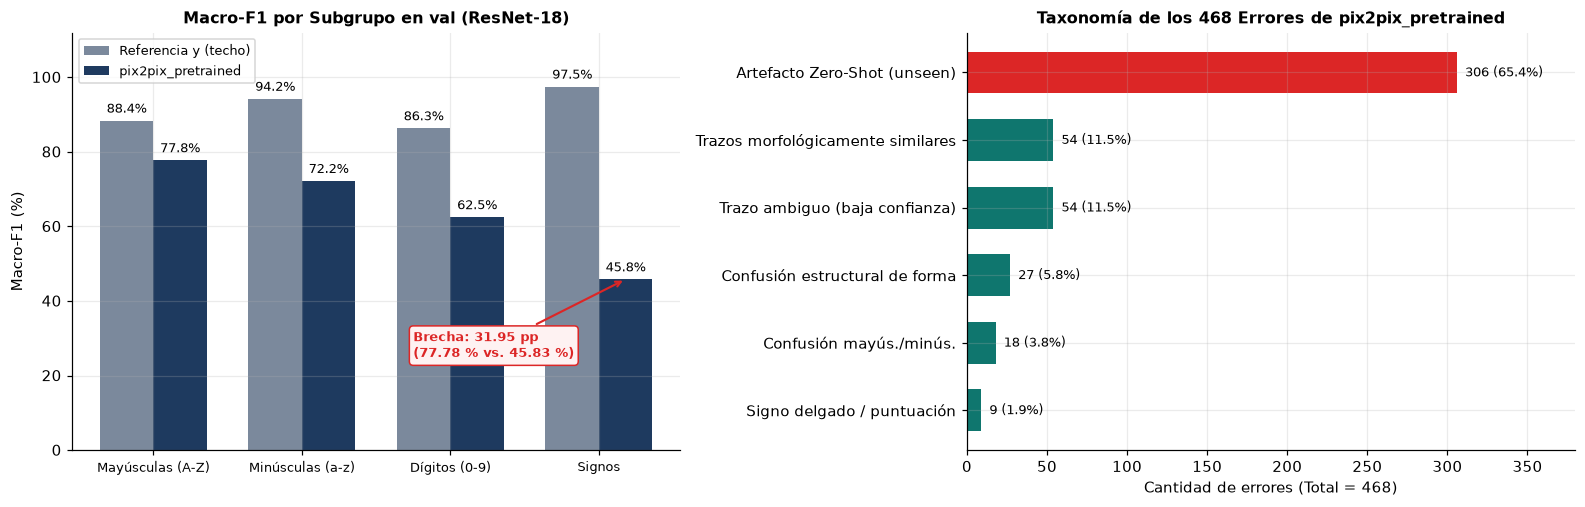

In [8]:
sub_json = json.loads((ROOT_DIR / "results" / "eval" / "auditoria_subgrupos_pretrain.json").read_text(encoding="utf-8"))
err_info = metrics_pretrain["error_analysis"]["pretrained"]

df_sub = pd.DataFrame(sub_json["subgroup_table"])
df_sub_val_r18 = df_sub[(df_sub["split"] == "val") & (df_sub["judge"] == "resnet18")].copy()
df_worst = pd.DataFrame(sub_json["worst_characters"])
df_unseen_chars = pd.DataFrame(sub_json["unseen_characters"])
err_counts = pd.Series(err_info["counts_by_category"]).sort_values(ascending=True)

assert abs(sub_json["val_gap_macro_f1_pp"] - 31.95) < 1e-6
assert err_info["total_errors"] == 468
assert int(err_counts.sum()) == 468

print(
    f"Brecha Macro-F1 verificada en val (ResNet-18): {sub_json['val_best_subgroup']} vs. {sub_json['val_worst_subgroup']} "
    f"= {sub_json['val_gap_macro_f1_pp']:.2f} pp | Total errores auditados: {err_info['total_errors']}"
)

display(Markdown("#### Desglose por subgrupo en `val` (juez `ResNet-18`, `reference_y` vs. `pix2pix_pretrained`)"))
display(
    df_sub_val_r18[["source", "subgroup", "n_samples", "n_classes", "accuracy", "macro_f1", "mean_conf", "pass_070_pct", "mean_l1"]]
    .sort_values(["source", "macro_f1"], ascending=[True, False])
    .reset_index(drop=True)
)

display(Markdown("#### 12 peores caracteres (`val` + `test_unseen`) y desempeño individual de los 11 símbolos Zero-Shot"))
display(df_worst)
display(df_unseen_chars)

# Gráfica en vivo: Macro-F1 por subgrupo (val) + Taxonomía de 468 errores
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7))

sub_order = ["Mayúsculas (A-Z)", "Minúsculas (a-z)", "Dígitos (0-9)", "Signos"]
ref_f1 = df_sub_val_r18[df_sub_val_r18["source"] == "reference_y"].set_index("subgroup").loc[sub_order, "macro_f1"]
pre_f1 = df_sub_val_r18[df_sub_val_r18["source"] == "pretrained"].set_index("subgroup").loc[sub_order, "macro_f1"]

x = np.arange(len(sub_order))
w = 0.36
b_ref = axes[0].bar(x - w / 2, ref_f1, w, label="Referencia y (techo)", color=PALETTE["slate"], alpha=0.85)
b_pre = axes[0].bar(x + w / 2, pre_f1, w, label="pix2pix_pretrained", color=PALETTE["navy"])
for bars in (b_ref, b_pre):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.3, f"{b.get_height():.1f}%", ha="center", va="bottom", fontsize=8.3)
axes[0].annotate(
    "Brecha: 31.95 pp\n(77.78 % vs. 45.83 %)",
    xy=(3 + w / 2, 45.83),
    xytext=(1.75, 25),
    arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.4),
    fontsize=8.6,
    fontweight="bold",
    color=PALETTE["coral"],
    bbox=dict(boxstyle="round,pad=0.3", fc="#FEF2F2", ec=PALETTE["coral"]),
)
axes[0].set_xticks(x)
axes[0].set_xticklabels(sub_order, fontsize=8.8)
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Macro-F1 (%)")
axes[0].set_title("Macro-F1 por Subgrupo en val (ResNet-18)")
axes[0].legend(fontsize=8.3, loc="upper left")

bar_colors = [PALETTE["coral"] if "Zero-Shot" in k else PALETTE["teal"] for k in err_counts.index]
b_err = axes[1].barh(err_counts.index, err_counts.values, color=bar_colors, height=0.62)
for b in b_err:
    pct = 100.0 * b.get_width() / err_info["total_errors"]
    axes[1].text(b.get_width() + 5, b.get_y() + b.get_height() / 2, f"{int(b.get_width())} ({pct:.1f}%)", va="center", fontsize=8.5)
axes[1].set_xlim(0, err_counts.max() * 1.24)
axes[1].set_xlabel("Cantidad de errores (Total = 468)")
axes[1].set_title("Taxonomía de los 468 Errores de pix2pix_pretrained")

plt.tight_layout()
plt.show()

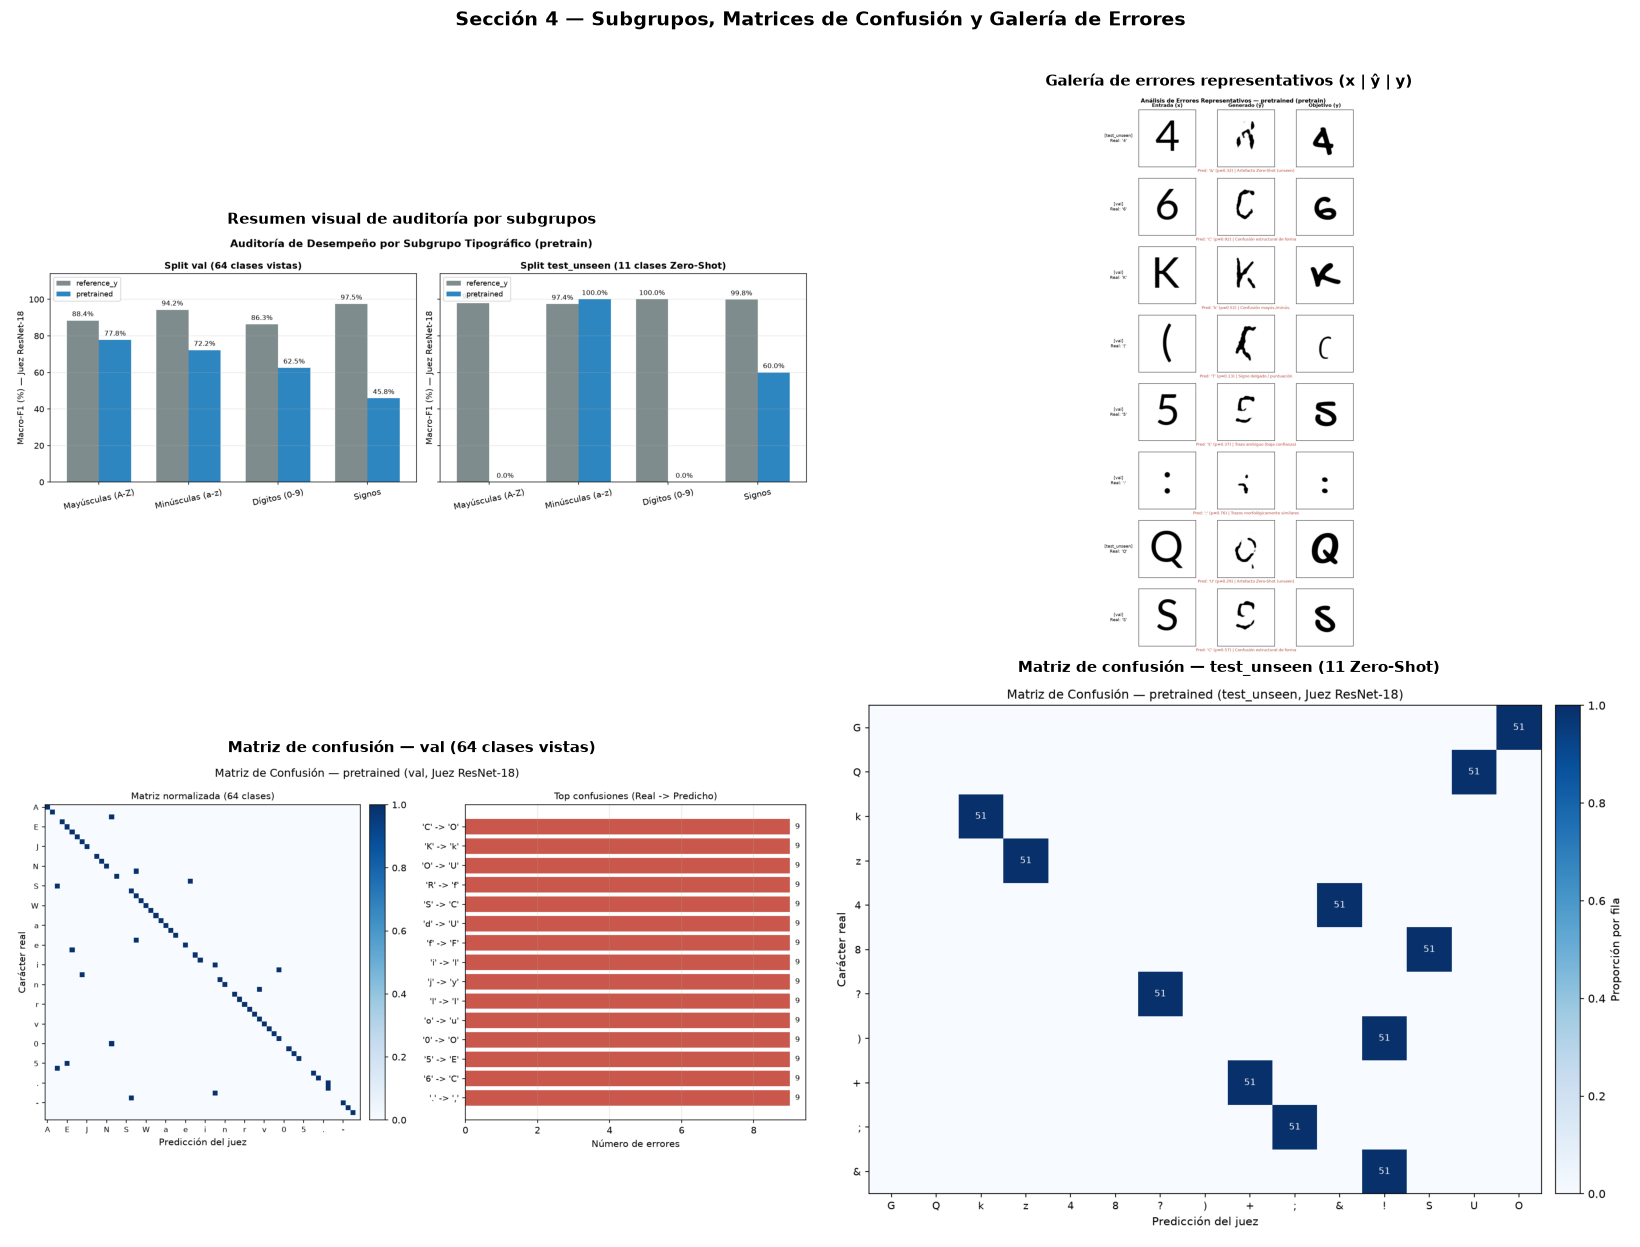

In [9]:
show_figure_grid(
    [
        ("docs/figuras/auditoria_subgrupos_pretrain.png", "Resumen visual de auditoría por subgrupos"),
        ("docs/figuras/eval_errores_pretrain_pretrained.png", "Galería de errores representativos (x | ŷ | y)"),
        ("docs/figuras/eval_cm_pretrain_pretrained_val.png", "Matriz de confusión — val (64 clases vistas)"),
        ("docs/figuras/eval_cm_pretrain_pretrained_test_unseen.png", "Matriz de confusión — test_unseen (11 Zero-Shot)"),
    ],
    ncols=2,
    figsize=(15.0, 11.2),
    suptitle="Sección 4 — Subgrupos, Matrices de Confusión y Galería de Errores",
)

---
## 5. Interpretabilidad Espacial (`Grad-CAM`)

> **Fuente técnica detallada:** [`eval/gradcam_analysis.py`](../eval/gradcam_analysis.py) · [`docs/interpretabilidad.md`](../docs/interpretabilidad.md)

Para confirmar que los clasificadores jueces fundamentan sus decisiones en los **trazos estructurales del glifo** y no en artefactos de fondo, aplicamos **Grad-CAM** sobre las capas convolucionales terminales de `ResNet-18` (`backbone.layer4[-1]`) y `EfficientNet-B0` (`backbone.features[-1]`), midiendo la **similitud coseno espacial** entre $\text{Grad-CAM}(y)$ y $\text{Grad-CAM}(\hat{y})$ en 80 muestras de `val` y 80 de `test_unseen` (`docs/interpretabilidad.md`).

### Cuatro causas físicas de error diagnosticadas con Grad-CAM
1. **Pérdida de bucles cerrados por promediado L1 multi-fuente (`6 → C`, `S → C`):** Al promediar 17 fuentes sintéticas con cierres en distintas alturas, el generador abre el bucle inferior del `6` o aplana la curva inferior de `S`, desplazando la atención hacia el costado abierto.
2. **Desaparición de puntos aislados (`! → l`, `i → l`):** Los puntos independientes representan muy pocos píxeles en la pérdida L1 global; al borrarse en `ŷ`, desaparece la activación puntual de `Grad-CAM(y)` y el juez predice el asta vertical `l`.
3. **Elongación local y ambigüedad *sans-serif* (`: → ;`, `l → I`):** Una pequeña cola descendente en el punto inferior de `:` dispara `;`, mientras `l` e `I` carecen de serifas distintivas incluso en la referencia `y` (`conf_y = 0.56`).
4. **Pérdida de cruces/colas en símbolos *Zero-Shot* complejos (`4 → &`, `Q → U`, `G → O`):** Todos producen confianza muy baja (`< 0.35`), confirmando que el umbral OOD `τ = 0.70` los intercepta automáticamente en la demo.

Además, la **validación cruzada entre jueces** (`ResNet-18` vs. `EfficientNet-B0`) confirma acuerdos espaciales muy altos (`cos = 0.90–0.95`) en glifos bien formados (`A, e, k, ?`), mientras que una divergencia fuerte en `g` (`cos = 0.40`, `ResNet-18: g (0.71)` vs. `EffNet: Y (0.41)`) delata una espuela espuria en la esquina superior derecha.

#### Alineación cuantitativa de atención espacial `Grad-CAM(y)` vs. `Grad-CAM(ŷ)`

,Split evaluado,N muestras,Coseno global (media ± DE),Coseno en aciertos,Coseno en errores,Brecha (Aciertos − Errores)
0,val (64 clases vistas),80,0.9734 ± 0.0443,0.9803,0.9619,0.0184
1,test_unseen (11 Zero-Shot),80,0.9536 ± 0.0434,0.9895,0.9257,0.0638


#### Consistencia entre evaluadores independientes (`ResNet-18` vs. `EfficientNet-B0`)

,split,true_char,resnet18_pred,resnet18_conf,effnet_pred,effnet_conf,cross_judge_cam_cos
0,val,A,A,0.8858,A,0.9418,0.9319
1,val,g,g,0.7082,Y,0.4100,0.3952
2,val,e,e,0.9680,e,0.9852,0.9437
3,test_unseen,k,k,0.9493,k,0.9622,0.9495
4,test_unseen,?,?,0.9775,?,0.9228,0.9038


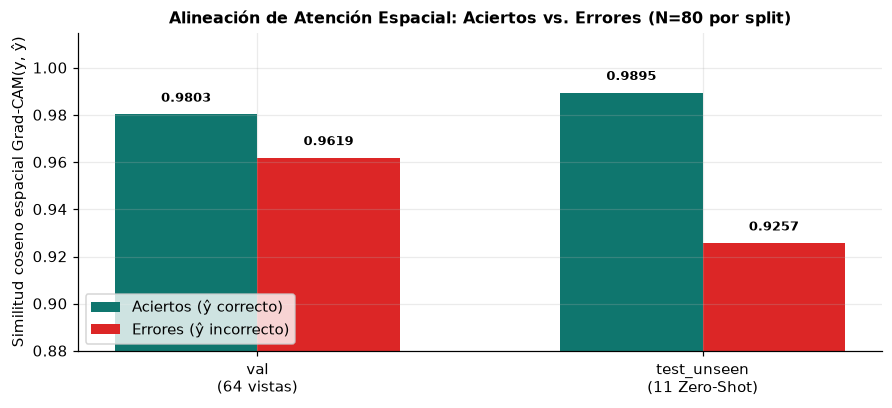

In [10]:
gcam = json.loads((ROOT_DIR / "results" / "eval" / "gradcam_pretrain.json").read_text(encoding="utf-8"))

align_rows = []
for key, label in [
    ("alignment_val", "val (64 clases vistas)"),
    ("alignment_test_unseen", "test_unseen (11 Zero-Shot)"),
]:
    a = gcam[key]
    align_rows.append(
        {
            "Split evaluado": label,
            "N muestras": a["n_evaluated"],
            "Coseno global (media ± DE)": f"{a['mean_cos_all']:.4f} ± {a['std_cos_all']:.4f}",
            "Coseno en aciertos": a["mean_cos_correct"],
            "Coseno en errores": a["mean_cos_wrong"],
            "Brecha (Aciertos − Errores)": round(a["mean_cos_correct"] - a["mean_cos_wrong"], 4),
        }
    )
df_align = pd.DataFrame(align_rows)
df_cross = pd.DataFrame(gcam["panels"]["resnet_vs_effnet"]["samples"])

display(Markdown("#### Alineación cuantitativa de atención espacial `Grad-CAM(y)` vs. `Grad-CAM(ŷ)`"))
display(df_align)

display(Markdown("#### Consistencia entre evaluadores independientes (`ResNet-18` vs. `EfficientNet-B0`)"))
display(df_cross)

# Gráfica en vivo de alineación coseno (Aciertos vs Errores)
fig, ax = plt.subplots(figsize=(8.2, 3.8))
splits_lbl = ["val\n(64 vistas)", "test_unseen\n(11 Zero-Shot)"]
x = np.arange(2)
w = 0.32
b_ok = ax.bar(x - w / 2, df_align["Coseno en aciertos"], w, label="Aciertos (ŷ correcto)", color=PALETTE["teal"])
b_er = ax.bar(x + w / 2, df_align["Coseno en errores"], w, label="Errores (ŷ incorrecto)", color=PALETTE["coral"])
for bars in (b_ok, b_er):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.004, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=8.8, fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(splits_lbl)
ax.set_ylim(0.88, 1.015)
ax.set_ylabel("Similitud coseno espacial Grad-CAM(y, ŷ)")
ax.set_title("Alineación de Atención Espacial: Aciertos vs. Errores (N=80 por split)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

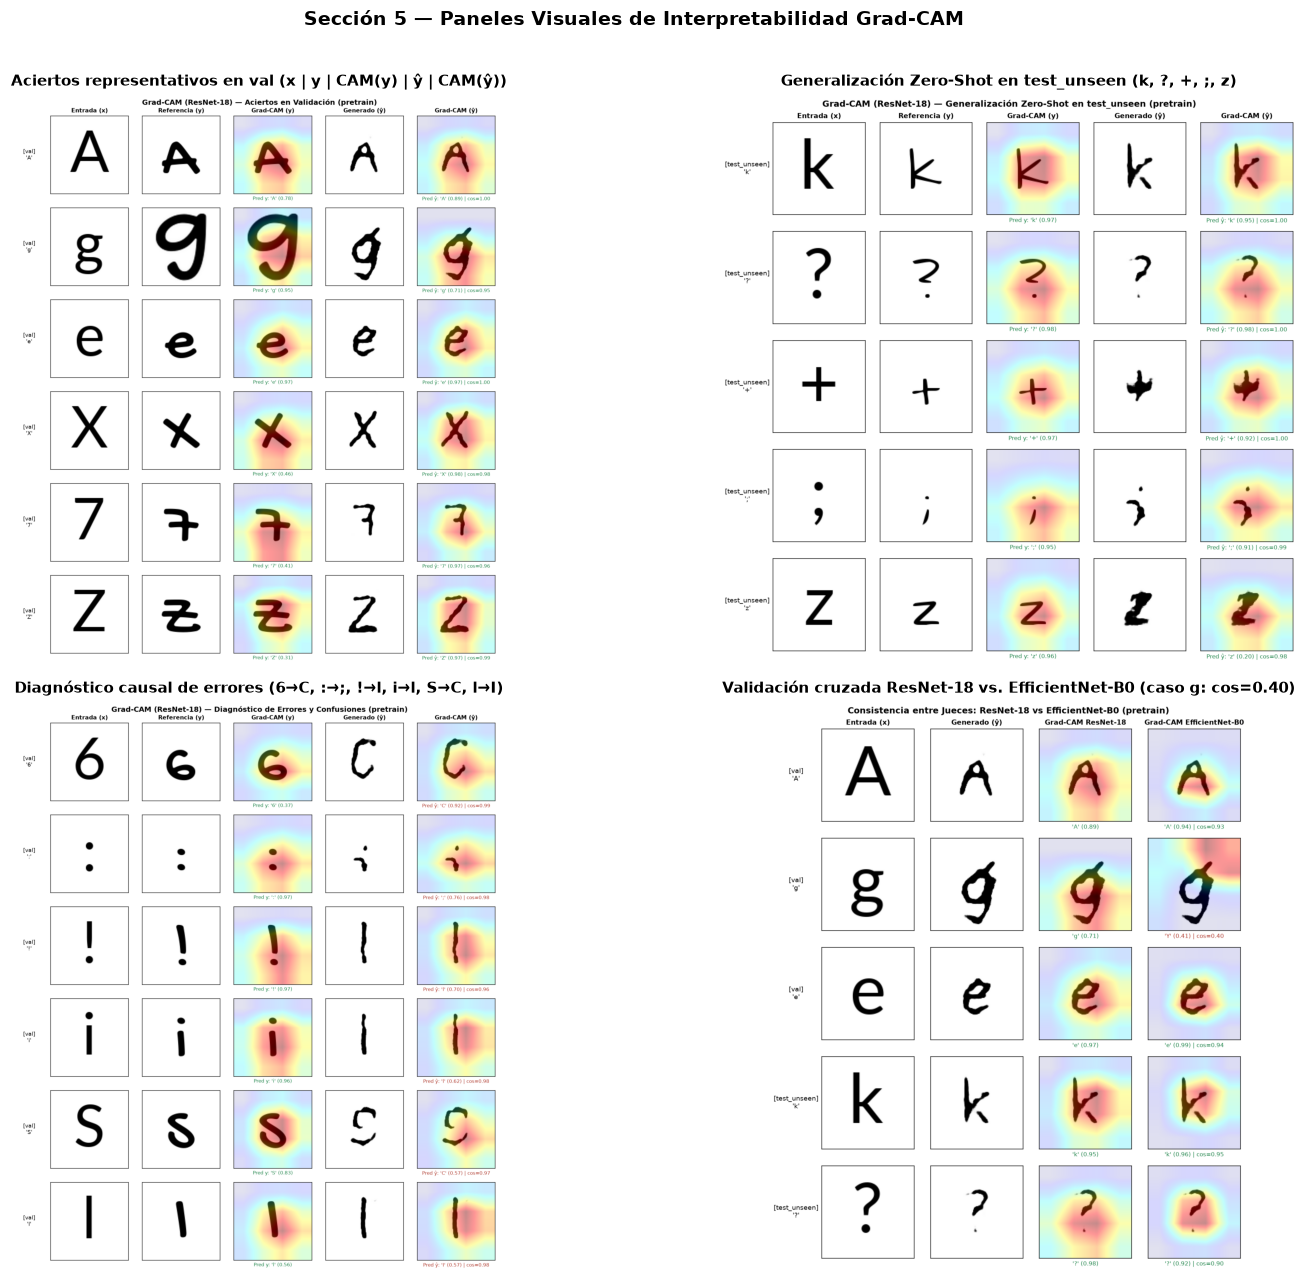

In [11]:
show_figure_grid(
    [
        ("docs/figuras/gradcam_pretrain_val_correctos.png", "Aciertos representativos en val (x | y | CAM(y) | ŷ | CAM(ŷ))"),
        ("docs/figuras/gradcam_pretrain_unseen_zeroshot.png", "Generalización Zero-Shot en test_unseen (k, ?, +, ;, z)"),
        ("docs/figuras/gradcam_pretrain_errores.png", "Diagnóstico causal de errores (6→C, :→;, !→l, i→l, S→C, l→I)"),
        ("docs/figuras/gradcam_pretrain_resnet_vs_effnet.png", "Validación cruzada ResNet-18 vs. EfficientNet-B0 (caso g: cos=0.40)"),
    ],
    ncols=2,
    figsize=(15.5, 11.5),
    suptitle="Sección 5 — Paneles Visuales de Interpretabilidad Grad-CAM",
)

---
## 6. Robustez OOD, Despliegue ONNX CPU e Inferencia Real en Vivo

> **Fuente técnica detallada:** [`eval/robustez.ipynb`](../eval/robustez.ipynb) · [`src/export/export_onnx.py`](../src/export/export_onnx.py) · [`src/export/export_style_onnx.py`](../src/export/export_style_onnx.py) · [`docs/robustez_y_despliegue.md`](../docs/robustez_y_despliegue.md)

### 6.1 Detección Fuera de Distribución (`72` imágenes OOD en 6 categorías)
- **Evaluación directa del juez (`ResNet-18`):** Alcanza **`AUROC = 0.9435`** (`77.8 %` de rechazo OOD a `τ = 0.70` con solo `10.8 %` de falso rechazo ID, y **`94.4 %`** en el óptimo Youden `τ = 0.85`), superando a `EfficientNet-B0` (`AUROC = 0.8856`).
- **Pipeline de la demo (`G + ResNet-18`, umbral por defecto `τ = 0.70`):** Rechaza el **`81.9 %`** global OOD, logrando **`100.0 %`** en `garabatos` y `simbolos_ineditos`, y **`91.7 %`** en `ruido_puro` y `rotacion_extrema`. En `desenfoque_corte` el rechazo en pipeline baja a `33.3 %` porque la U-Net actúa parcialmente como restaurador de trazos borrosos.

### 6.2 Optimización a ONNX Runtime en CPU
Exportar el generador (`generator.onnx`, `159.56 MB`) y el juez (`judge_resnet18.onnx`, `42.75 MB`) con `intra_op_num_threads=4` e `inter_op_num_threads=1` redujo la latencia del pipeline completo (`G + ResNet-18`) de **`35.61 ± 3.87 ms` (`28.08 FPS`)** en PyTorch CPU a **`21.07 ± 1.83 ms` (`p95 = 24.00 ms`, `47.45 FPS`)** en ONNX Runtime — un **speedup de `1.69×`** con error numérico máximo `< 1e-5` (`8.97e-06` en `G` y `1.91e-06` en `ResNet-18`), cumpliendo holgadamente la meta de tiempo real (`≥ 10 FPS / ≤ 100 ms`).

#### Evaluación OOD (`results/eval/robustez_ood.json`, N = 72 imágenes)

,Escenario,AUROC,Rechazo OOD @τ=0.70 (%),Falso rechazo ID @τ=0.70 (%),Óptimo Youden τ,Rechazo OOD óptimo (%)
0,ResNet-18 directo (y vs. OOD),0.9435,77.8,10.8,0.85,94.4
1,EfficientNet-B0 directo (y vs. OOD),0.8856,70.8,9.6,0.80,77.8
2,Pipeline Demo (G + ResNet-18),0.7574,81.9,39.1,0.75,90.3
3,Pipeline Demo (G + EfficientNet-B0),0.8162,81.9,39.1,0.55,76.4


,Categoría OOD,N,Conf. media R18 (directo),Rechazo R18 directo @0.70 (%),Rechazo EffNet directo @0.70 (%),Conf. media R18 (pipeline),Rechazo R18 pipeline @0.70 (%)
0,desenfoque_corte,12,0.3843,83.3,50.0,0.6817,33.3
1,garabatos,12,0.4371,83.3,100.0,0.2665,100.0
2,rotacion_extrema,12,0.4859,66.7,83.3,0.3759,91.7
3,ruido_puro,12,0.5131,58.3,66.7,0.4530,91.7
4,simbolos_ineditos,12,0.4311,75.0,66.7,0.3430,100.0
5,sombra_bajo_contraste,12,0.1964,100.0,58.3,0.6562,75.0


#### Benchmark CPU PyTorch vs. ONNX Runtime (`results/benchmark_onnx.json`, 100 inferencias, batch=1)

,Etapa,PyTorch CPU (ms),PyTorch FPS,ONNX CPU (ms),ONNX p95 (ms),ONNX FPS,Speedup,ONNX (MB),Error máx. abs.
0,Generador G (UNetGenerator),29.14 ± 3.99,34.31,16.86 ± 2.29,20.70,59.30,1.73×,159.56,8.97e-06
1,Juez (ResNet-18),8.47 ± 0.92,118.08,4.69 ± 0.78,5.88,213.22,1.81×,42.75,1.91e-06
2,Pipeline completo (G + Juez),35.61 ± 3.87,28.08,21.07 ± 1.83,24.00,47.45,1.69×,202.31,< 1e-5


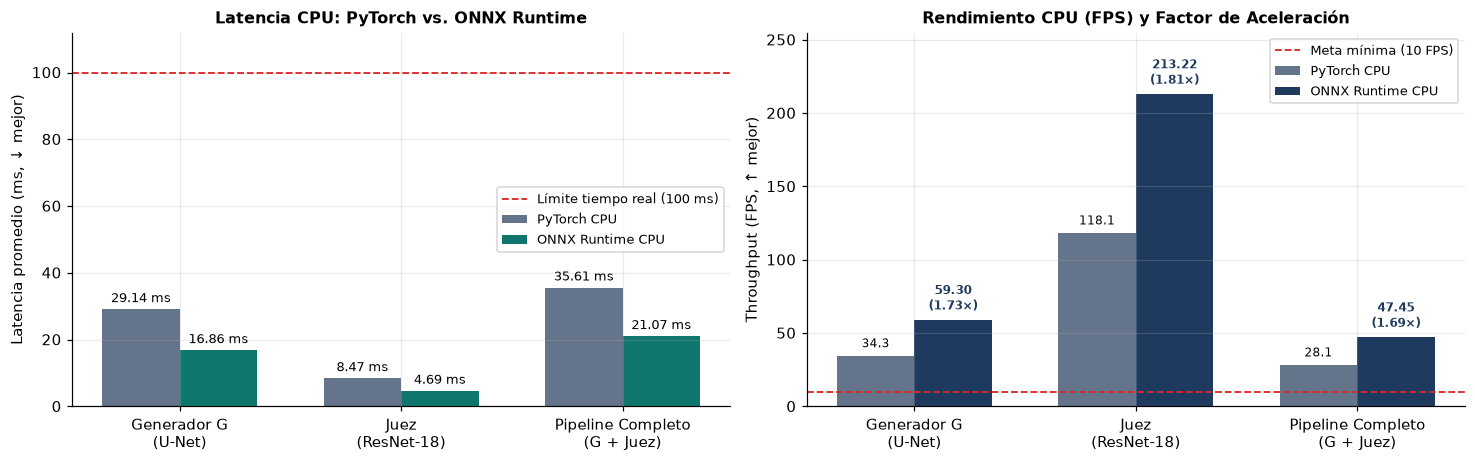

In [12]:
ood_json = json.loads((ROOT_DIR / "results" / "eval" / "robustez_ood.json").read_text(encoding="utf-8"))
bench_json = json.loads((ROOT_DIR / "results" / "benchmark_onnx.json").read_text(encoding="utf-8"))

# Tabla de escenarios OOD
scen_labels = {
    "resnet18_direct": "ResNet-18 directo (y vs. OOD)",
    "effnet_direct": "EfficientNet-B0 directo (y vs. OOD)",
    "resnet18_pipeline": "Pipeline Demo (G + ResNet-18)",
    "effnet_pipeline": "Pipeline Demo (G + EfficientNet-B0)",
}
scen_rows = []
for k, lbl in scen_labels.items():
    s = ood_json["scenarios"][k]
    scen_rows.append(
        {
            "Escenario": lbl,
            "AUROC": s["auroc"],
            "Rechazo OOD @τ=0.70 (%)": round(s["ood_rejection_at_070"] * 100, 1),
            "Falso rechazo ID @τ=0.70 (%)": round(s["id_false_rejection_at_070"] * 100, 1),
            "Óptimo Youden τ": s["best_youden_tau"],
            "Rechazo OOD óptimo (%)": round(s["best_youden_ood_rejection"] * 100, 1),
        }
    )
df_ood_scen = pd.DataFrame(scen_rows)
df_ood_cat = pd.DataFrame(ood_json["by_category"])

# Tabla Benchmark PyTorch vs ONNX Runtime
pt = bench_json["pytorch_cpu"]
ox = bench_json["onnxruntime_cpu"]
sp = bench_json["speedup"]
bench_rows = []
for key, label, size_key, diff_key in [
    ("generator", "Generador G (UNetGenerator)", "generator_onnx", "generator"),
    ("judge", "Juez (ResNet-18)", "judge_onnx", "judge"),
    ("pipeline", "Pipeline completo (G + Juez)", None, None),
]:
    bench_rows.append(
        {
            "Etapa": label,
            "PyTorch CPU (ms)": f"{pt[key]['mean_ms']:.2f} ± {pt[key]['std_ms']:.2f}",
            "PyTorch FPS": pt[key]["fps"],
            "ONNX CPU (ms)": f"{ox[key]['mean_ms']:.2f} ± {ox[key]['std_ms']:.2f}",
            "ONNX p95 (ms)": ox[key]["p95_ms"],
            "ONNX FPS": ox[key]["fps"],
            "Speedup": f"{sp[key]:.2f}×",
            "ONNX (MB)": bench_json["sizes_mb"][size_key] if size_key else round(sum(bench_json["sizes_mb"].values()), 2),
            "Error máx. abs.": f"{bench_json['max_abs_diff'][diff_key]:.2e}" if diff_key else "< 1e-5",
        }
    )
df_bench = pd.DataFrame(bench_rows)

display(Markdown("#### Evaluación OOD (`results/eval/robustez_ood.json`, N = 72 imágenes)"))
display(df_ood_scen)
display(df_ood_cat)

display(Markdown("#### Benchmark CPU PyTorch vs. ONNX Runtime (`results/benchmark_onnx.json`, 100 inferencias, batch=1)"))
display(df_bench)

# Gráfica comparativa PyTorch vs ONNX (Latencia ms y Throughput FPS)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.3))
stages = ["Generador G\n(U-Net)", "Juez\n(ResNet-18)", "Pipeline Completo\n(G + Juez)"]
keys = ["generator", "judge", "pipeline"]
x = np.arange(len(stages))
w = 0.35

pt_ms = [pt[k]["mean_ms"] for k in keys]
ox_ms = [ox[k]["mean_ms"] for k in keys]
pt_fps = [pt[k]["fps"] for k in keys]
ox_fps = [ox[k]["fps"] for k in keys]

b1 = axes[0].bar(x - w / 2, pt_ms, w, label="PyTorch CPU", color=PALETTE["slate"])
b2 = axes[0].bar(x + w / 2, ox_ms, w, label="ONNX Runtime CPU", color=PALETTE["teal"])
axes[0].axhline(100.0, color=PALETTE["coral"], linestyle="--", lw=1.2, label="Límite tiempo real (100 ms)")
for bars in (b1, b2):
    for b in bars:
        axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 1.2, f"{b.get_height():.2f} ms", ha="center", va="bottom", fontsize=8.3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(stages)
axes[0].set_ylim(0, 112)
axes[0].set_ylabel("Latencia promedio (ms, ↓ mejor)")
axes[0].set_title("Latencia CPU: PyTorch vs. ONNX Runtime")
axes[0].legend(fontsize=8.2)

b3 = axes[1].bar(x - w / 2, pt_fps, w, label="PyTorch CPU", color=PALETTE["slate"])
b4 = axes[1].bar(x + w / 2, ox_fps, w, label="ONNX Runtime CPU", color=PALETTE["navy"])
axes[1].axhline(10.0, color=PALETTE["coral"], linestyle="--", lw=1.2, label="Meta mínima (10 FPS)")
for i, (b_p, b_o) in enumerate(zip(b3, b4)):
    axes[1].text(b_p.get_x() + b_p.get_width() / 2, b_p.get_height() + 4, f"{b_p.get_height():.1f}", ha="center", va="bottom", fontsize=8.1)
    axes[1].text(
        b_o.get_x() + b_o.get_width() / 2,
        b_o.get_height() + 4,
        f"{b_o.get_height():.2f}\n({sp[keys[i]]:.2f}×)",
        ha="center",
        va="bottom",
        fontsize=8.1,
        fontweight="bold",
        color=PALETTE["navy"],
    )
axes[1].set_xticks(x)
axes[1].set_xticklabels(stages)
axes[1].set_ylim(0, 255)
axes[1].set_ylabel("Throughput (FPS, ↑ mejor)")
axes[1].set_title("Rendimiento CPU (FPS) y Factor de Aceleración")
axes[1].legend(fontsize=8.2)

plt.tight_layout()
plt.show()

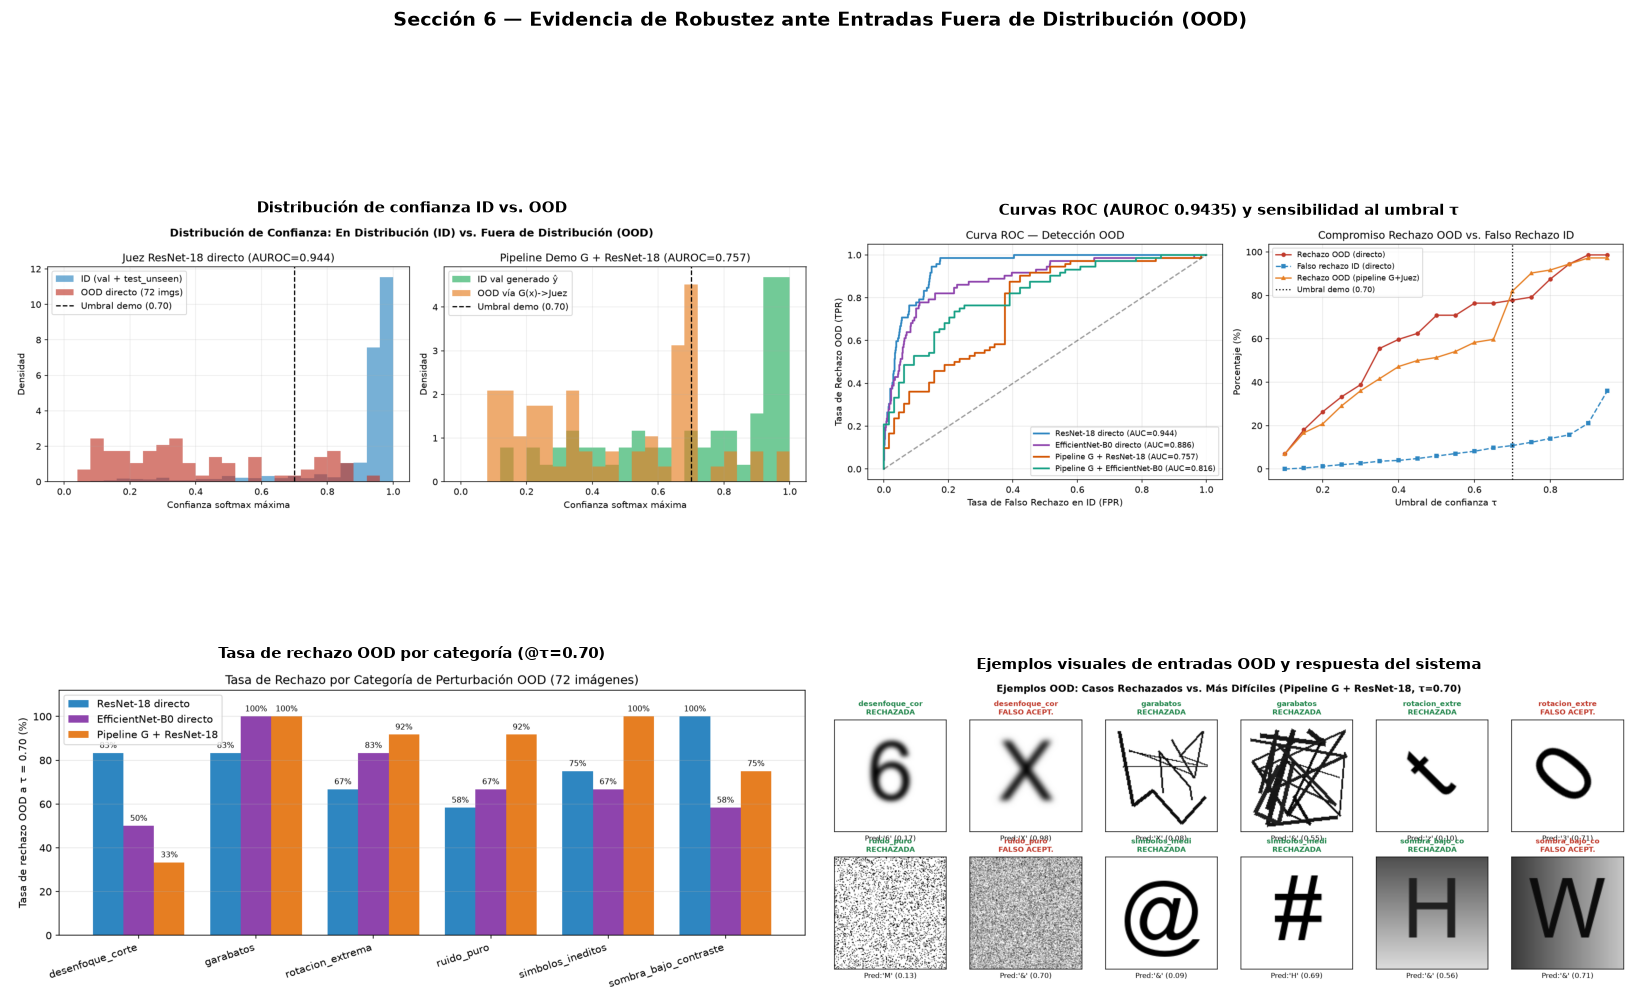

In [13]:
show_figure_grid(
    [
        ("docs/figuras/robustez_ood_distribucion.png", "Distribución de confianza ID vs. OOD"),
        ("docs/figuras/robustez_ood_roc_umbral.png", "Curvas ROC (AUROC 0.9435) y sensibilidad al umbral τ"),
        ("docs/figuras/robustez_ood_categorias.png", "Tasa de rechazo OOD por categoría (@τ=0.70)"),
        ("docs/figuras/robustez_ood_ejemplos.png", "Ejemplos visuales de entradas OOD y respuesta del sistema"),
    ],
    ncols=2,
    figsize=(15.0, 10.2),
    suptitle="Sección 6 — Evidencia de Robustez ante Entradas Fuera de Distribución (OOD)",
)

### 6.3 Inferencia Real en Vivo en CPU (`Pix2Pix` vs. `StyleUNet` + `ResNet-18` ONNX)

A continuación cargamos directamente las sesiones reales de **ONNX Runtime en CPU** y comparamos lado a lado ambos generadores exportados — **`checkpoints/generator.onnx` (`Pix2Pix`)** y **`checkpoints/style_unet.onnx` (`StyleUNet`, exportado vía `src/export/export_style_onnx.py` con 4 trazos reales propios `['A', 'R', 'e', 's']` precalculados en `z_style`)** — auditados por **`checkpoints/judge_resnet18.onnx`** sobre **6 imágenes reales leídas del disco**:
- **2 ejemplos vistos de `val`** (`A` y `e` de `data/synthetic_pairs/val/x/`).
- **2 ejemplos *Zero-Shot* de `test_unseen`** (`?` y `Q` de `data/synthetic_pairs/test_unseen/x/`).
- **2 ejemplos OOD de `data/ood/`** (`garabatos` y `simbolos_ineditos` `'@'`).

Además, la demo interactiva en tiempo real (`python app/demo_realtime.py`) permite alternar en vivo **Pix2Pix ↔ StyleUNet** mediante botones en el encabezado (o `Ctrl+G`), normalizar trazos libres de mouse (`_normalize_freehand_canvas`) y evaluar directamente `x` normalizado en modo mouse/webcam (`Enter` alterna `x directo` vs. generador).

[OK] Inferencia ONNX en vivo (6 muestras en CPU) | Pix2Pix+Juez: 66.34 ms (15.1 FPS) | StyleUNet+Juez: 73.13 ms (13.7 FPS)


,Grupo,Real,Pix2Pix Pred,Pix2Pix Conf,Pix2Pix ms,StyleUNet Pred,StyleUNet Conf,StyleUNet ms,Veredicto StyleUNet (τ=0.70)
0,Visto (val),'A','A',0.8858,59.30,'A',0.9202,68.75,OK
1,Visto (val),'e','e',0.9680,76.89,'e',0.8452,80.17,OK
2,Zero-Shot (test_unseen),'?','?',0.9775,74.04,'?',0.2521,77.30,OOD / BAJA
3,Zero-Shot (test_unseen),'Q','U',0.2907,69.66,'O',0.7315,72.79,OK
4,OOD (garabatos),OOD: garabato,'X',0.0837,60.18,':',0.2138,70.78,OOD / BAJA
5,OOD (simbolos_ineditos),OOD: '@','&',0.2259,57.98,'E',0.1630,69.00,OOD / BAJA


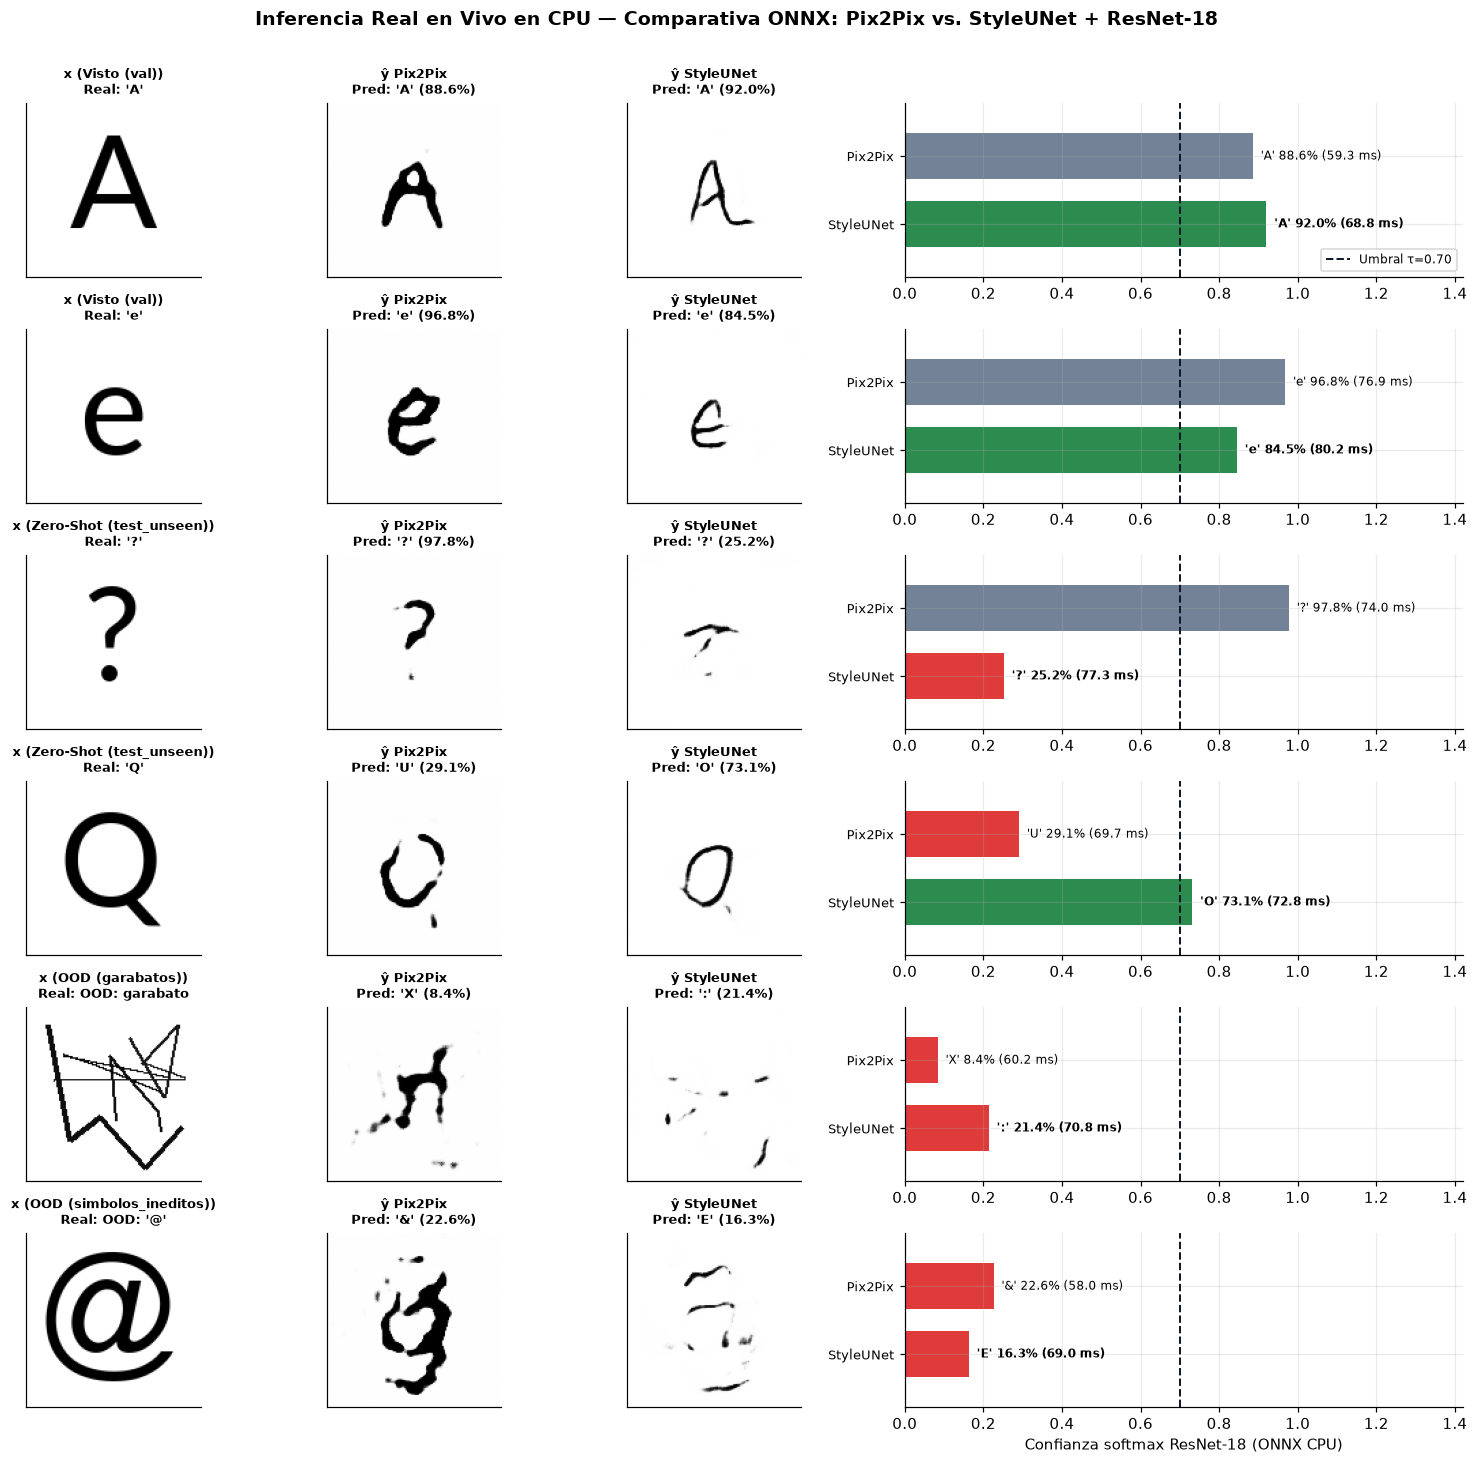

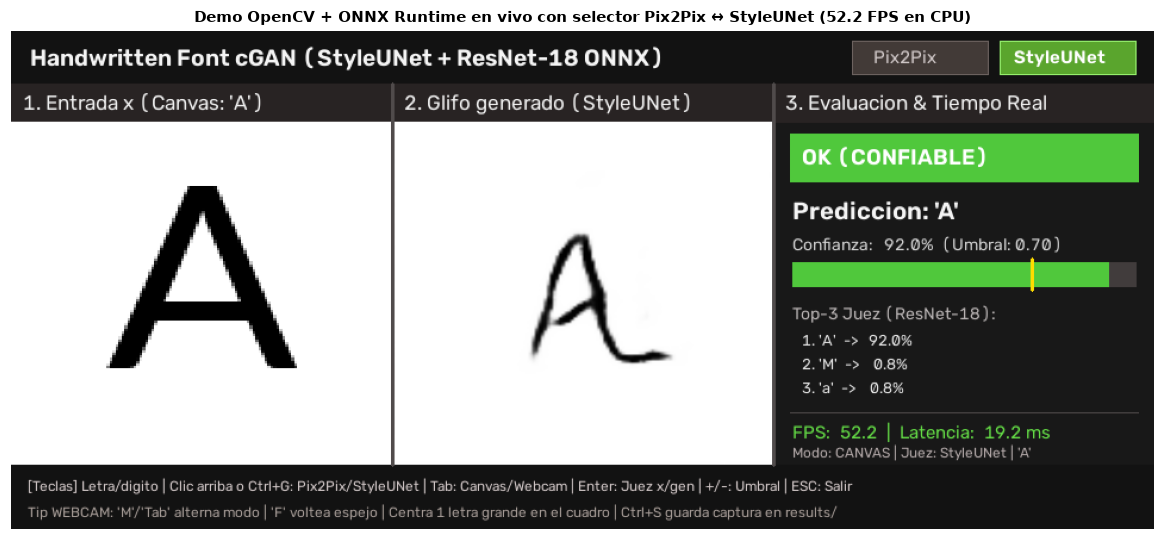

In [14]:
from src.config import IDX_TO_CHAR

TAU_OOD = 0.70
gen_onnx_path = ROOT_DIR / "checkpoints" / "generator.onnx"
style_onnx_path = ROOT_DIR / "checkpoints" / "style_unet.onnx"
judge_onnx_path = ROOT_DIR / "checkpoints" / "judge_resnet18.onnx"
assert gen_onnx_path.exists() and judge_onnx_path.exists(), "Faltan modelos ONNX base en checkpoints/"
has_style_onnx = style_onnx_path.exists()


def _make_session(path: Path) -> ort.InferenceSession:
    opts = ort.SessionOptions()
    opts.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    opts.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    opts.intra_op_num_threads = min(4, os.cpu_count() or 4)
    opts.inter_op_num_threads = 1
    # Evitar contención de spin-wait entre múltiples sesiones ONNX y el pool OpenMP de PyTorch
    opts.add_session_config_entry("session.intra_op.allow_spinning", "0")
    return ort.InferenceSession(str(path), sess_options=opts, providers=["CPUExecutionProvider"])


torch.set_num_threads(1)


def _softmax(logits: np.ndarray) -> np.ndarray:
    shifted = logits - np.max(logits)
    exps = np.exp(shifted)
    return exps / np.sum(exps)


gen_sess = _make_session(gen_onnx_path)
style_sess = _make_session(style_onnx_path) if has_style_onnx else None
judge_sess = _make_session(judge_onnx_path)

# Calentamiento breve en CPU (3 corridas) para medir latencia en régimen estable
dummy_x = np.zeros((1, 1, 128, 128), dtype=np.float32)
for _ in range(3):
    y_warm = gen_sess.run(["y_hat"], {"x": dummy_x})[0]
    _ = judge_sess.run(["logits"], {"glyph": y_warm})[0]
    if style_sess is not None:
        ys_warm = style_sess.run(["y_hat"], {"x": dummy_x})[0]
        _ = judge_sess.run(["logits"], {"glyph": ys_warm})[0]

# Selección determinista de 6 ejemplos reales en disco (2 val, 2 test_unseen, 2 OOD)
val_a = syn_df[(syn_df["split"] == "val") & (syn_df["char"] == "A")].iloc[0]
val_e = syn_df[(syn_df["split"] == "val") & (syn_df["char"] == "e")].iloc[0]
uns_qmark = syn_df[(syn_df["split"] == "test_unseen") & (syn_df["char"] == "?")].iloc[0]
uns_Q = syn_df[(syn_df["split"] == "test_unseen") & (syn_df["char"] == "Q")].iloc[0]
ood_scribble = ood_df[ood_df["category"] == "garabatos"].iloc[0]
ood_symbol = ood_df[ood_df["category"] == "simbolos_ineditos"].iloc[0]

live_cases = [
    ("Visto (val)", f"'{val_a['char']}'", ROOT_DIR / "data" / "synthetic_pairs" / val_a["x_path"]),
    ("Visto (val)", f"'{val_e['char']}'", ROOT_DIR / "data" / "synthetic_pairs" / val_e["x_path"]),
    ("Zero-Shot (test_unseen)", f"'{uns_qmark['char']}'", ROOT_DIR / "data" / "synthetic_pairs" / uns_qmark["x_path"]),
    ("Zero-Shot (test_unseen)", f"'{uns_Q['char']}'", ROOT_DIR / "data" / "synthetic_pairs" / uns_Q["x_path"]),
    ("OOD (garabatos)", "OOD: garabato", ROOT_DIR / "data" / "ood" / ood_scribble["image_path"]),
    ("OOD (simbolos_ineditos)", f"OOD: '{ood_symbol['source_char']}'", ROOT_DIR / "data" / "ood" / ood_symbol["image_path"]),
]


def _run_pipeline(sess: ort.InferenceSession, x_in: np.ndarray) -> tuple[np.ndarray, str, float, str, float, float, float]:
    t0 = time.perf_counter()
    y_hat = sess.run(["y_hat"], {"x": x_in})[0]
    t1 = time.perf_counter()
    logits = judge_sess.run(["logits"], {"glyph": y_hat})[0][0]
    t2 = time.perf_counter()
    probs = _softmax(logits)
    top_idx = int(np.argmax(probs))
    pred_char = IDX_TO_CHAR[top_idx]
    conf = float(probs[top_idx])
    verdict = "OK" if conf >= TAU_OOD else "OOD / BAJA"
    y_u8 = np.clip((y_hat[0, 0] + 1.0) * 127.5, 0.0, 255.0).astype(np.uint8)
    return y_u8, pred_char, conf, verdict, (t1 - t0) * 1000.0, (t2 - t1) * 1000.0, (t2 - t0) * 1000.0


live_records = []
live_visuals = []

for group, true_lbl, img_path in live_cases:
    assert img_path.exists(), f"No existe la muestra de inferencia: {img_path}"
    x_u8 = np.array(Image.open(img_path).convert("L").resize((128, 128)), dtype=np.uint8)
    x_in = ((x_u8.astype(np.float32) / 127.5) - 1.0)[None, None, :, :]

    p2p_u8, p2p_pred, p2p_conf, p2p_verd, p2p_g, p2p_j, p2p_tot = _run_pipeline(gen_sess, x_in)
    row = {
        "Grupo": group,
        "Real": true_lbl,
        "Pix2Pix Pred": f"'{p2p_pred}'",
        "Pix2Pix Conf": round(p2p_conf, 4),
        "Pix2Pix ms": round(p2p_tot, 2),
    }
    style_tuple = None
    if style_sess is not None:
        st_u8, st_pred, st_conf, st_verd, st_g, st_j, st_tot = _run_pipeline(style_sess, x_in)
        row.update(
            {
                "StyleUNet Pred": f"'{st_pred}'",
                "StyleUNet Conf": round(st_conf, 4),
                "StyleUNet ms": round(st_tot, 2),
                f"Veredicto StyleUNet (τ={TAU_OOD:.2f})": st_verd,
            }
        )
        style_tuple = (st_u8, st_pred, st_conf, st_verd, st_tot)
    else:
        row[f"Veredicto (τ={TAU_OOD:.2f})"] = p2p_verd

    live_records.append(row)
    live_visuals.append((group, true_lbl, x_u8, (p2p_u8, p2p_pred, p2p_conf, p2p_verd, p2p_tot), style_tuple))

df_live = pd.DataFrame(live_records)
mean_p2p_ms = float(df_live["Pix2Pix ms"].mean())
summary_msg = (
    f"[OK] Inferencia ONNX en vivo (6 muestras en CPU) | "
    f"Pix2Pix+Juez: {mean_p2p_ms:.2f} ms ({1000.0 / mean_p2p_ms:.1f} FPS)"
)
if style_sess is not None:
    mean_st_ms = float(df_live["StyleUNet ms"].mean())
    summary_msg += f" | StyleUNet+Juez: {mean_st_ms:.2f} ms ({1000.0 / mean_st_ms:.1f} FPS)"
print(summary_msg)
display(df_live)

# Visualización lado a lado: x | ŷ Pix2Pix | ŷ StyleUNet | Comparativa Confianza & Latencia
ncols = 4 if style_sess is not None else 3
ratios = [1.0, 1.0, 1.0, 2.55] if style_sess is not None else [1.0, 1.0, 2.35]
fig, axes = plt.subplots(
    len(live_visuals),
    ncols,
    figsize=(13.6 if style_sess is not None else 11.8, 13.2),
    gridspec_kw={"width_ratios": ratios},
)

for row_idx, (group, true_lbl, x_u8, p2p_info, st_info) in enumerate(live_visuals):
    p2p_u8, p2p_pred, p2p_conf, p2p_verd, p2p_ms = p2p_info
    ax_x = axes[row_idx, 0]
    ax_p2p = axes[row_idx, 1]

    ax_x.imshow(x_u8, cmap="gray", vmin=0, vmax=255)
    ax_x.set_title(f"x ({group})\nReal: {true_lbl}", fontsize=8.5)
    ax_x.set_xticks([])
    ax_x.set_yticks([])

    ax_p2p.imshow(p2p_u8, cmap="gray", vmin=0, vmax=255)
    ax_p2p.set_title(f"ŷ Pix2Pix\nPred: '{p2p_pred}' ({p2p_conf*100:.1f}%)", fontsize=8.5)
    ax_p2p.set_xticks([])
    ax_p2p.set_yticks([])

    if st_info is not None:
        st_u8, st_pred, st_conf, st_verd, st_ms = st_info
        ax_st = axes[row_idx, 2]
        ax_info = axes[row_idx, 3]

        ax_st.imshow(st_u8, cmap="gray", vmin=0, vmax=255)
        ax_st.set_title(f"ŷ StyleUNet\nPred: '{st_pred}' ({st_conf*100:.1f}%)", fontsize=8.5)
        ax_st.set_xticks([])
        ax_st.set_yticks([])

        c_p2p = PALETTE["slate"] if p2p_conf >= TAU_OOD else PALETTE["coral"]
        c_st = PALETTE["green"] if st_conf >= TAU_OOD else PALETTE["coral"]
        ax_info.barh([0.28, -0.28], [p2p_conf, st_conf], color=[c_p2p, c_st], height=0.38, alpha=0.9)
        ax_info.axvline(TAU_OOD, color="#111827", linestyle="--", lw=1.3, label=f"Umbral τ={TAU_OOD:.2f}")
        ax_info.set_xlim(0.0, 1.42)
        ax_info.set_ylim(-0.72, 0.72)
        ax_info.set_yticks([0.28, -0.28])
        ax_info.set_yticklabels(["Pix2Pix", "StyleUNet"], fontsize=8.4)
        ax_info.text(p2p_conf + 0.02, 0.28, f"'{p2p_pred}' {p2p_conf*100:.1f}% ({p2p_ms:.1f} ms)", va="center", fontsize=8.0)
        ax_info.text(st_conf + 0.02, -0.28, f"'{st_pred}' {st_conf*100:.1f}% ({st_ms:.1f} ms)", va="center", fontsize=8.0, fontweight="bold")
        if row_idx == 0:
            ax_info.legend(loc="lower right", fontsize=7.8)
    else:
        ax_info = axes[row_idx, 2]
        bar_color = PALETTE["green"] if p2p_conf >= TAU_OOD else PALETTE["coral"]
        ax_info.barh([0], [p2p_conf], color=bar_color, height=0.42, alpha=0.88)
        ax_info.axvline(TAU_OOD, color="#111827", linestyle="--", lw=1.4)
        ax_info.set_xlim(0.0, 1.05)
        ax_info.set_yticks([])

    if row_idx == len(live_visuals) - 1:
        ax_info.set_xlabel("Confianza softmax ResNet-18 (ONNX CPU)")

fig.suptitle(
    "Inferencia Real en Vivo en CPU — Comparativa ONNX: Pix2Pix vs. StyleUNet + ResNet-18",
    fontsize=12.2,
    fontweight="bold",
    y=1.004,
)
plt.tight_layout()
plt.show()

# Captura real de la demo interactiva OpenCV con selector en vivo Pix2Pix <-> StyleUNet
demo_cap = ROOT_DIR / "results" / "demo_headless_ok.png"
if demo_cap.exists():
    show_figure_grid(
        [("results/demo_headless_ok.png", "Demo OpenCV + ONNX Runtime en vivo con selector Pix2Pix ↔ StyleUNet (52.2 FPS en CPU)")],
        ncols=1,
        figsize=(11.5, 5.0),
    )

---
## 7. Producto Final (`.ttf`), Trazabilidad Ética, Costos y Limitaciones

> **Fuente técnica detallada:** [`src/export/build_ttf.py`](../src/export/build_ttf.py) · [`docs/costos.md`](../docs/costos.md) · [`MODEL_CARD.md`](../MODEL_CARD.md)

### 7.1 Compilación de tipografía instalable `.ttf` y trazabilidad ética
El módulo `src/export/build_ttf.py` vectoriza cada glifo (`128×128` → `256×256` vía `vtracer` en modo spline), convierte curvas cúbicas a cuadráticas TrueType (`Cu2QuPen`), calcula métricas horizontales proporcionales (`hmtx`) y empaqueta un `.ttf` instalable con `fontTools.FontBuilder`:
- **Modo sintético (`HandwrittenCGAN_Pretrain.ttf`):** 84 glifos (75 `CHARSET` + 9 inéditos `@ # $ % ñ Ñ ¿ ¡ *`) sintetizados con `generator.onnx`, incrustando el marcador de trazabilidad **`AI-SYNTHETIC`** directamente en la tabla OpenType `name`.
- **Modo personal fiel (`MiLetra_Stylus.ttf`):** Selecciona automáticamente el **medoide L1** entre las 4 repeticiones reales de cada carácter (`data/real_pairs/`) y en la versión actual de `build_ttf.py` incrusta el marcador **`PERSONAL-STYLUS`** (uso personal autorizado).

### 7.2 Limitaciones técnicas y éticas clave (`README.md`, `MODEL_CARD.md`)
1. **Glifos aislados (`1×128×128`):** No modela ligaduras cursivas continuas ni presión dinámica entre caracteres adyacentes.
2. **Choque de dominio en trazos finos:** Sin desacoplamiento de estilo (`Pix2Pix` base), el stylus real (`2.57 %` tinta) penaliza *Zero-Shot*; `StyleUNet` resuelve gran parte del problema (`72.73 %` *Zero-Shot*), aunque los signos y trazos muy finos siguen siendo el subgrupo más sensible.
3. **Pares morfológicamente ambiguos y convenciones personales:** `l/I/1`, `0/O/o`, puntos aislados (`!`, `i`, `:`) y estilos propios (como el cero tachado `0 → Ø`) concentran la mayoría de desacuerdos.
4. **Tamaño de muestra *Zero-Shot* (`n = 11` clases):** Cada carácter pesa `~9.09 pp` en Accuracy, introduciendo alta varianza estadística en comparaciones finas.
5. **Cobertura ASCII base (`75` clases):** Caracteres extendidos del español (`ñ, Ñ, ¿, ¡`) se generan solo en inferencia como experimentales.
6. **Uso responsable:** Prohibida la suplantación de identidad o falsificación de firmas/documentos sin consentimiento explícito; los `.ttf` portan metadatos de procedencia en su tabla OpenType `name`.

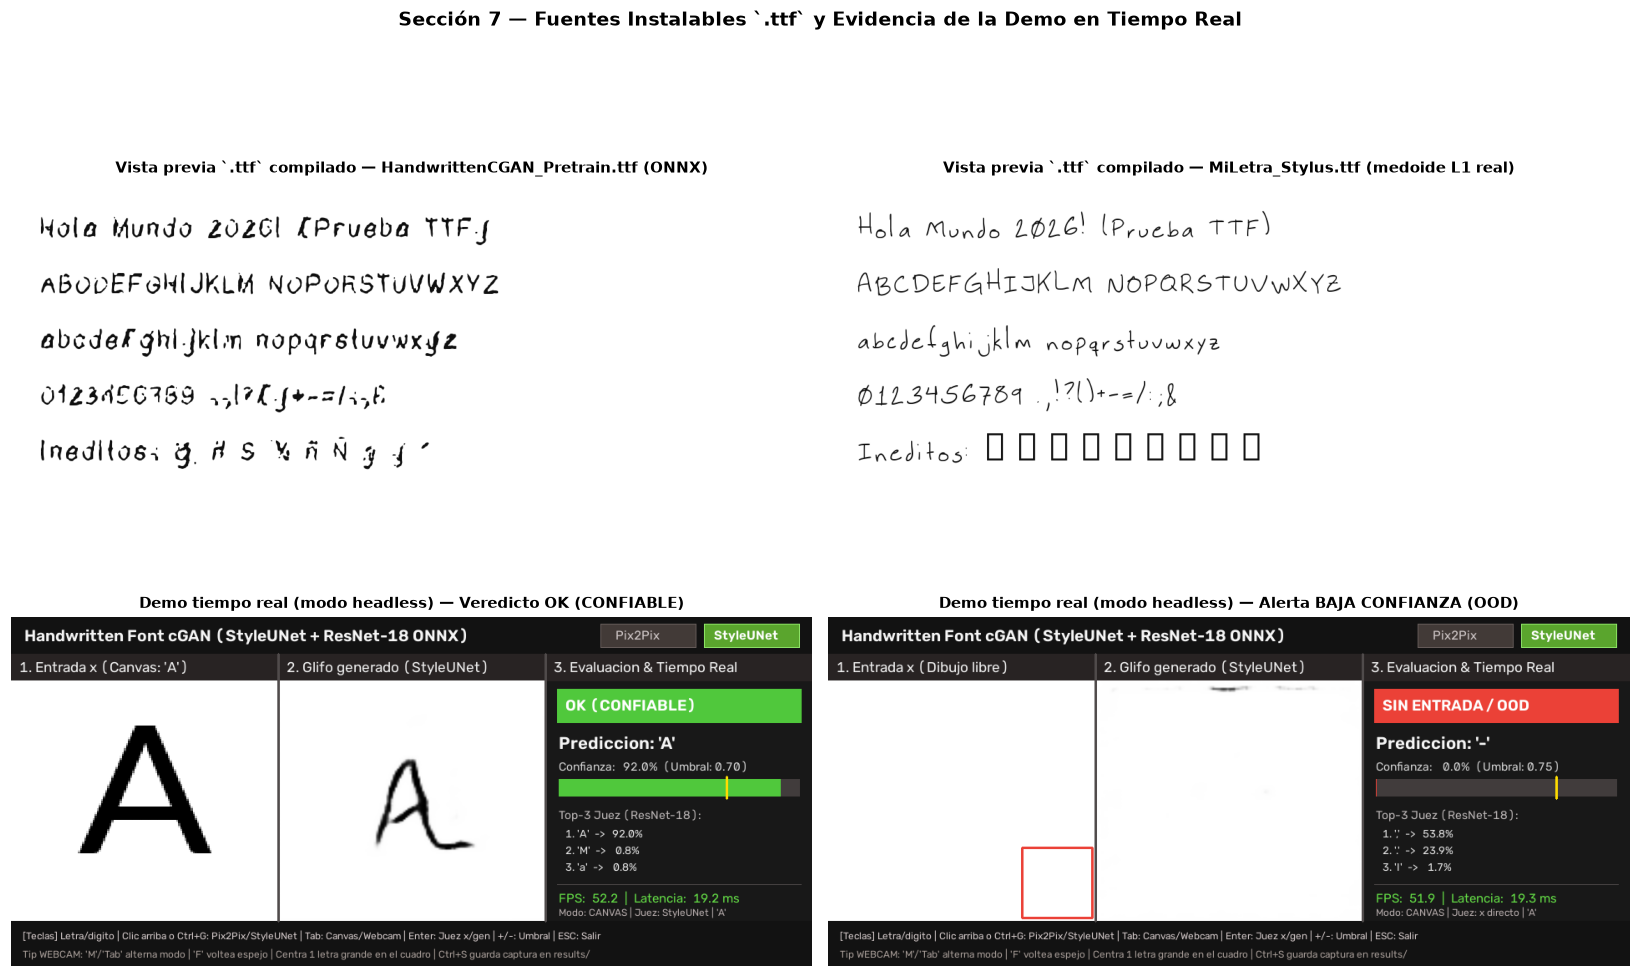

In [15]:
show_figure_grid(
    [
        ("results/font_preview.png", "Vista previa `.ttf` compilado — HandwrittenCGAN_Pretrain.ttf (ONNX)"),
        ("results/font_preview_stylus.png", "Vista previa `.ttf` compilado — MiLetra_Stylus.ttf (medoide L1 real)"),
        ("results/demo_headless_ok.png", "Demo tiempo real (modo headless) — Veredicto OK (CONFIABLE)"),
        ("results/demo_headless_ood.png", "Demo tiempo real (modo headless) — Alerta BAJA CONFIANZA (OOD)"),
    ],
    ncols=2,
    figsize=(15.0, 9.6),
    suptitle="Sección 7 — Fuentes Instalables `.ttf` y Evidencia de la Demo en Tiempo Real",
)

In [16]:
from fontTools.ttLib import TTFont

NAME_ID_LABELS = {
    0: "Copyright",
    1: "Family Name",
    2: "Subfamily",
    3: "Unique Font ID",
    4: "Full Name",
    5: "Version",
    6: "PostScript Name",
    8: "Manufacturer",
    9: "Designer",
    10: "Description (Trazabilidad)",
    13: "License Description",
}

ttf_files = sorted((ROOT_DIR / "results").glob("*.ttf"))
assert len(ttf_files) >= 1, "No se encontraron archivos .ttf en results/"

meta_rows = []
for ttf_path in ttf_files:
    font = TTFont(str(ttf_path))
    n_glyphs = len(font.getGlyphOrder())
    size_kb = ttf_path.stat().st_size / 1024.0
    name_table = font["name"]
    # Leer registros Windows Unicode (platformID=3) para evitar duplicados Mac/Win
    seen_ids = set()
    markers_found = []
    for rec in name_table.names:
        if rec.platformID == 3 and rec.nameID not in seen_ids:
            seen_ids.add(rec.nameID)
            val = rec.toUnicode()
            for tag in ("AI-SYNTHETIC", "PERSONAL-STYLUS"):
                if tag in val:
                    markers_found.append(tag)
            meta_rows.append(
                {
                    "Archivo .ttf": ttf_path.name,
                    "Glifos": n_glyphs,
                    "Tamaño (KB)": round(size_kb, 1),
                    "nameID": rec.nameID,
                    "Campo OpenType": NAME_ID_LABELS.get(rec.nameID, f"ID {rec.nameID}"),
                    "Valor incrustado en disco": val,
                }
            )
    font.close()
    marker_str = ", ".join(sorted(set(markers_found))) if markers_found else "(compilado antes de agregar marcador PERSONAL-STYLUS en build_ttf.py)"
    print(f"[TTF] {ttf_path.name:28s} | {n_glyphs:2d} glifos | {size_kb:5.1f} KB | Marcadores detectados: {marker_str}")

df_ttf_meta = pd.DataFrame(meta_rows)
display(Markdown("#### Metadatos OpenType (`name` table) leídos dinámicamente de `results/*.ttf` con `fontTools`"))
display(df_ttf_meta)

# Verificar en código fuente (`src/export/build_ttf.py`) que ambos marcadores de procedencia existen
build_ttf_src = (ROOT_DIR / "src" / "export" / "build_ttf.py").read_text(encoding="utf-8")
assert "AI-SYNTHETIC" in build_ttf_src and "PERSONAL-STYLUS" in build_ttf_src
print(
    "[OK] Verificado en `src/export/build_ttf.py`: ambos marcadores de trazabilidad "
    "(`AI-SYNTHETIC` para fuentes ONNX y `PERSONAL-STYLUS` para fuentes medoide stylus) "
    "están implementados en el compilador OpenType."
)

[TTF] HandwrittenCGAN_Pretrain.ttf | 86 glifos |  36.2 KB | Marcadores detectados: AI-SYNTHETIC
[TTF] MiLetra_Stylus.ttf           | 77 glifos |  21.3 KB | Marcadores detectados: (compilado antes de agregar marcador PERSONAL-STYLUS en build_ttf.py)


#### Metadatos OpenType (`name` table) leídos dinámicamente de `results/*.ttf` con `fontTools`

,Archivo .ttf,Glifos,Tamaño (KB),nameID,Campo OpenType,Valor incrustado en disco
0,HandwrittenCGAN_Pretrain.ttf,86,36.2,0,Copyright,Synthetic AI-generated font (Handwritten Font cGAN / Pix2Pix). Not for identity impersonation or forgery.
1,HandwrittenCGAN_Pretrain.ttf,86,36.2,1,Family Name,HandwrittenCGAN
2,HandwrittenCGAN_Pretrain.ttf,86,36.2,2,Subfamily,Regular
3,HandwrittenCGAN_Pretrain.ttf,86,36.2,3,Unique Font ID,HandwrittenCGAN-Regular-AI-Generated
4,HandwrittenCGAN_Pretrain.ttf,86,36.2,4,Full Name,HandwrittenCGAN Regular
5,HandwrittenCGAN_Pretrain.ttf,86,36.2,5,Version,Version 1.000
6,HandwrittenCGAN_Pretrain.ttf,86,36.2,6,PostScript Name,HandwrittenCGAN-Regular
7,HandwrittenCGAN_Pretrain.ttf,86,36.2,8,Manufacturer,Handwritten Font cGAN Pipeline (Pix2Pix + vtracer + fontTools)
8,HandwrittenCGAN_Pretrain.ttf,86,36.2,9,Designer,Synthetic AI Output (HandwrittenFont-Pix2Pix-cGAN)
9,HandwrittenCGAN_Pretrain.ttf,86,36.2,10,Description (Trazabilidad),AI-generated synthetic handwriting font produced glyph-by-glyph with Pix2Pix cGAN (1x128x128) and vectoriz...


[OK] Verificado en `src/export/build_ttf.py`: ambos marcadores de trazabilidad (`AI-SYNTHETIC` para fuentes ONNX y `PERSONAL-STYLUS` para fuentes medoide stylus) están implementados en el compilador OpenType.


#### Desglose de costos medidos en GPU NVIDIA Tesla T4 (`docs/costos.md`)

,Etapa / Modelo,Dataset,Épocas,Mejor ep.,Tiempo T4 (s),Tiempo (min),Checkpoint (MB),Costo real ($),Equiv. T4 $0.35/h ($)
0,Juez ResNet-18,"Sintético (3,825)",30,23,99.9,1.67,42.84,0.0,0.010
1,Juez EfficientNet-B0,"Sintético (3,825)",22,15,117.3,1.96,15.95,0.0,0.011
2,Pix2Pix Pretrain,"Sintético (2,688)",60,11,832.6,13.88,170.16,0.0,0.081
3,Pix2Pix Fine-Tune,Real stylus (192),100,51,235.0,3.92,170.16,0.0,0.023
4,Pix2Pix Scratch,Real stylus (192),150,120,309.1,5.15,170.16,0.0,0.030
5,StyleUNet Pretrain,"Sintético (2,688)",60,59,2782.9,46.38,180.00,0.0,0.271
6,StyleUNet Fine-Tune,Real stylus (192),40,4,157.0,2.62,180.00,0.0,0.015
7,TOTAL CICLO GPU,—,462,—,4533.8,75.58,929.30,0.0,0.441


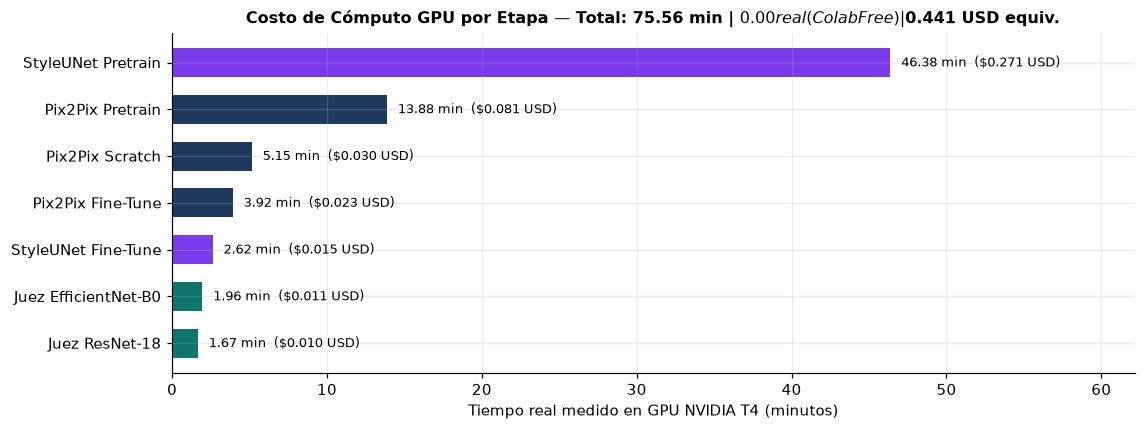


Resumen económico de escalabilidad:
  • Entrenamiento completo ejecutado : $0.00 USD (Google Colab Free + PC local) | $0.441 USD comercial T4
  • Inferencia en producción         : $0.00 GPU (ONNX Runtime CPU en cliente a 47.45 FPS / 21.07 ms)
  • Personalización por usuario      : $0.00 en StyleUNet Few-Shot (4 refs) o ~$0.015 USD en Fine-Tune ligero (2.62 min T4)


In [17]:
# Resumen cuantitativo de costos medidos en GPU T4 y CPU local (`docs/costos.md`)
cost_rows = [
    {"Etapa / Modelo": "Juez ResNet-18", "Dataset": "Sintético (3,825)", "Épocas": 30, "Mejor ep.": 23, "Tiempo T4 (s)": 99.9, "Tiempo (min)": 1.67, "Checkpoint (MB)": 42.84, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.010},
    {"Etapa / Modelo": "Juez EfficientNet-B0", "Dataset": "Sintético (3,825)", "Épocas": 22, "Mejor ep.": 15, "Tiempo T4 (s)": 117.3, "Tiempo (min)": 1.96, "Checkpoint (MB)": 15.95, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.011},
    {"Etapa / Modelo": "Pix2Pix Pretrain", "Dataset": "Sintético (2,688)", "Épocas": 60, "Mejor ep.": 11, "Tiempo T4 (s)": 832.6, "Tiempo (min)": 13.88, "Checkpoint (MB)": 170.16, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.081},
    {"Etapa / Modelo": "Pix2Pix Fine-Tune", "Dataset": "Real stylus (192)", "Épocas": 100, "Mejor ep.": 51, "Tiempo T4 (s)": 235.0, "Tiempo (min)": 3.92, "Checkpoint (MB)": 170.16, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.023},
    {"Etapa / Modelo": "Pix2Pix Scratch", "Dataset": "Real stylus (192)", "Épocas": 150, "Mejor ep.": 120, "Tiempo T4 (s)": 309.1, "Tiempo (min)": 5.15, "Checkpoint (MB)": 170.16, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.030},
    {"Etapa / Modelo": "StyleUNet Pretrain", "Dataset": "Sintético (2,688)", "Épocas": 60, "Mejor ep.": 59, "Tiempo T4 (s)": 2782.9, "Tiempo (min)": 46.38, "Checkpoint (MB)": 180.0, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.271},
    {"Etapa / Modelo": "StyleUNet Fine-Tune", "Dataset": "Real stylus (192)", "Épocas": 40, "Mejor ep.": 4, "Tiempo T4 (s)": 157.0, "Tiempo (min)": 2.62, "Checkpoint (MB)": 180.0, "Costo real ($)": 0.0, "Equiv. T4 $0.35/h ($)": 0.015},
]
df_costs = pd.DataFrame(cost_rows)
totals_row = {
    "Etapa / Modelo": "TOTAL CICLO GPU",
    "Dataset": "—",
    "Épocas": int(df_costs["Épocas"].sum()),
    "Mejor ep.": "—",
    "Tiempo T4 (s)": round(float(df_costs["Tiempo T4 (s)"].sum()), 1),
    "Tiempo (min)": round(float(df_costs["Tiempo (min)"].sum()), 2),
    "Checkpoint (MB)": round(float(df_costs["Checkpoint (MB)"].sum()), 1),
    "Costo real ($)": 0.0,
    "Equiv. T4 $0.35/h ($)": round(float(df_costs["Equiv. T4 $0.35/h ($)"].sum()), 3),
}
assert totals_row["Épocas"] == 462
assert abs(totals_row["Tiempo T4 (s)"] - 4533.8) < 1e-6
assert abs(totals_row["Equiv. T4 $0.35/h ($)"] - 0.441) < 1e-6

df_costs_display = pd.concat([df_costs, pd.DataFrame([totals_row])], ignore_index=True)
display(Markdown("#### Desglose de costos medidos en GPU NVIDIA Tesla T4 (`docs/costos.md`)"))
display(df_costs_display)

# Gráfica de tiempo y costo comercial equivalente por etapa
fig, ax = plt.subplots(figsize=(10.5, 4.0))
plot_c = df_costs.sort_values("Tiempo (min)", ascending=True)
c_bars = [PALETTE["purple"] if "StyleUNet" in s else (PALETTE["teal"] if "Juez" in s else PALETTE["navy"]) for s in plot_c["Etapa / Modelo"]]
bars = ax.barh(plot_c["Etapa / Modelo"], plot_c["Tiempo (min)"], color=c_bars, height=0.62)
for b, usd in zip(bars, plot_c["Equiv. T4 $0.35/h ($)"]):
    ax.text(b.get_width() + 0.7, b.get_y() + b.get_height() / 2, f"{b.get_width():.2f} min  (${usd:.3f} USD)", va="center", fontsize=8.5)
ax.set_xlabel("Tiempo real medido en GPU NVIDIA T4 (minutos)")
ax.set_xlim(0, plot_c["Tiempo (min)"].max() * 1.34)
ax.set_title("Costo de Cómputo GPU por Etapa — Total: 75.56 min | $0.00 real (Colab Free) | $0.441 USD equiv.")
plt.tight_layout()
plt.show()

print(
    "\nResumen económico de escalabilidad:\n"
    "  • Entrenamiento completo ejecutado : $0.00 USD (Google Colab Free + PC local) | $0.441 USD comercial T4\n"
    "  • Inferencia en producción         : $0.00 GPU (ONNX Runtime CPU en cliente a 47.45 FPS / 21.07 ms)\n"
    "  • Personalización por usuario      : $0.00 en StyleUNet Few-Shot (4 refs) o ~$0.015 USD en Fine-Tune ligero (2.62 min T4)"
)